In [168]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [212]:
living_room_loc='//content/drive/MyDrive/pipeline_output/generated/living_room/extracted'
bedroom_loc='/content/drive/MyDrive/pipeline_output/generated/bedroom/extracted'
bathroom_loc='/content/drive/MyDrive/pipeline_output/generated/bathroom/extracted'
hallway_loc='/content/drive/MyDrive/pipeline_output/generated/hallway/extracted'
toilet_loc='/content/drive/MyDrive/pipeline_output/generated/toilet/extracted'

In [213]:
segmented_rooms='/content/drive/MyDrive/pipeline_output/segmentation/00000010.png'

In [214]:
import os
import glob
import numpy as np
import cv2
from PIL import Image
import matplotlib.pyplot as plt
import random
from itertools import product
import json

In [215]:
def load_all_room_images(room_folders):
    """
    Load all extracted room images from each room type folder.
    Groups images by room instance (e.g., bedroom_1, bedroom_2).

    Parameters:
    -----------
    room_folders : dict
        Dictionary with room types as keys and folder paths as values

    Returns:
    --------
    room_images : dict
        Dictionary with room identifiers (e.g., 'bedroom_1', 'bedroom_2') as keys
        and lists of (image_path, image_array) tuples
    """
    room_images = {}

    for room_type, folder_path in room_folders.items():
        if not os.path.exists(folder_path):
            print(f"Warning: {room_type} folder not found at {folder_path}")
            continue

        # Get all PNG files in the folder
        image_files = glob.glob(os.path.join(folder_path, "*.png"))

        # Group images by room instance
        # e.g., bedroom_1_extracted_1.png -> bedroom_1
        #       bedroom_2_extracted_1.png -> bedroom_2
        room_instances = {}

        for img_path in image_files:
            filename = os.path.basename(img_path)

            # Try to extract room instance identifier
            # Pattern: roomtype_NUMBER_... or just roomtype_...
            parts = filename.split('_')

            # Check if there's a number after room type
            if len(parts) >= 2 and parts[1].isdigit():
                room_instance = f"{room_type}_{parts[1]}"
            else:
                # Single instance of this room type
                room_instance = room_type

            # Load image
            img = cv2.imread(img_path, cv2.IMREAD_UNCHANGED)
            if img is not None:
                # Convert from BGR(A) to RGB(A)
                if len(img.shape) == 3 and img.shape[2] == 4:
                    img = cv2.cvtColor(img, cv2.COLOR_BGRA2RGBA)
                elif len(img.shape) == 3:
                    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

                if room_instance not in room_instances:
                    room_instances[room_instance] = []
                room_instances[room_instance].append((img_path, img))

        # Add all room instances to the main dictionary
        for room_instance, images in room_instances.items():
            room_images[room_instance] = images
            print(f"Loaded {len(images)} images for {room_instance}")

    return room_images

In [ ]:
# Add this cell after loading room images to filter for a SINGLE floor plan

def get_rooms_for_floor_plan(room_images, floor_plan_id):
    """
    Get only the rooms that belong to a specific floor plan.
    
    Parameters:
    -----------
    room_images : dict
        All loaded room images
    floor_plan_id : str
        The floor plan identifier (e.g., '00000010', '00000001')
        
    Returns:
    --------
    filtered_rooms : dict
        Only rooms belonging to this floor plan
    """
    filtered_rooms = {}
    
    for room_key, images in room_images.items():
        # Check if this room belongs to the specified floor plan
        # Pattern: room_type or room_type_FLOORPLANID
        
        if floor_plan_id in room_key:
            # This room belongs to our floor plan
            filtered_rooms[room_key] = images
            print(f"  ✓ Including: {room_key} ({len(images)} images)")
        elif '_' not in room_key or not any(char.isdigit() for char in room_key.split('_')[-1]):
            # Generic room without floor plan ID (e.g., 'living_room', 'bedroom')
            # Only include if no floor-plan-specific version exists
            pass  # Skip generic rooms if we have specific ones
            
    return filtered_rooms


def get_available_floor_plans(room_images):
    """
    Identify all unique floor plan IDs from loaded room images.
    
    Returns:
    --------
    floor_plan_ids : list
        List of unique floor plan identifiers
    """
    floor_plan_ids = set()
    
    for room_key in room_images.keys():
        parts = room_key.split('_')
        # Look for numeric parts that could be floor plan IDs
        for part in parts:
            if part.isdigit() and len(part) >= 5:  # Floor plan IDs like '00000010'
                floor_plan_ids.add(part)
                
    return sorted(list(floor_plan_ids))


# ============================================================================
# DISCOVER AVAILABLE FLOOR PLANS
# ============================================================================
print("="*60)
print("DISCOVERING AVAILABLE FLOOR PLANS")
print("="*60)

available_floor_plans = get_available_floor_plans(room_images)
print(f"\nFound {len(available_floor_plans)} floor plans:")
for fp_id in available_floor_plans:
    # Count rooms for this floor plan
    room_count = sum(1 for k in room_images.keys() if fp_id in k)
    print(f"  • Floor Plan {fp_id}: {room_count} room types")

print("\n" + "="*60)

In [216]:
def create_floor_plan_combination(room_images, base_size):
    """
    Create one floor plan by randomly selecting one image from each room type
    and overlaying them all on a white canvas.

    Parameters:
    -----------
    room_images : dict
        Dictionary with room types as keys and lists of (image_path, image_array) tuples
    base_size : tuple
        (height, width) of the canvas

    Returns:
    --------
    floor_plan : numpy.ndarray
        Combined floor plan image
    selected_rooms : dict
        Information about which room images were used
    """
    # Create white background canvas (RGB)
    canvas = np.ones((base_size[0], base_size[1], 3), dtype=np.uint8) * 255

    selected_rooms = {}

    # For each room type, randomly pick one image and overlay it
    for room_type, images in room_images.items():
        if len(images) == 0:
            continue

        # Randomly select one image from this room type
        img_path, room_img = random.choice(images)

        # Resize if needed
        if room_img.shape[:2] != (base_size[0], base_size[1]):
            room_img = cv2.resize(room_img, (base_size[1], base_size[0]), interpolation=cv2.INTER_AREA)

        # If the image has an alpha channel, use it for blending
        if room_img.shape[2] == 4:
            # Extract RGB and alpha
            room_rgb = room_img[:, :, :3]
            alpha = room_img[:, :, 3:4] / 255.0

            # Blend onto canvas
            canvas = (alpha * room_rgb + (1 - alpha) * canvas).astype(np.uint8)
        else:
            # No alpha, just overlay where pixels are not white
            mask = ~np.all(room_img == 255, axis=2)
            canvas[mask] = room_img[mask]

        selected_rooms[room_type] = os.path.basename(img_path)

    return canvas, selected_rooms

In [217]:
def fill_empty_rooms_with_floor(canvas, segmented_mask_path):
    """
    Detect unfilled regions in the segmented mask and fill them with a floor color.

    Parameters:
    -----------
    canvas : numpy.ndarray
        The current floor plan canvas
    segmented_mask_path : str
        Path to the segmented rooms mask

    Returns:
    --------
    canvas : numpy.ndarray
        Canvas with empty rooms filled
    """
    # Load the segmented mask
    mask = cv2.imread(segmented_mask_path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        return canvas

    # Resize mask to match canvas if needed
    if mask.shape[:2] != canvas.shape[:2]:
        mask = cv2.resize(mask, (canvas.shape[1], canvas.shape[0]), interpolation=cv2.INTER_NEAREST)

    # Threshold to get room regions
    _, binary_mask = cv2.threshold(mask, 1, 255, cv2.THRESH_BINARY)

    # Find where the canvas is still white (unfilled)
    white_pixels = np.all(canvas == 255, axis=2)

    # Find unfilled regions that should be rooms (in the mask but still white)
    unfilled_rooms = white_pixels & (binary_mask > 0)

    if np.any(unfilled_rooms):
        print("Found unfilled room region(s), filling with floor color...")

        # Generate a random floor color (beige/tan/light brown tones)
        floor_colors = [
            [230, 220, 200],  # Light beige
            [220, 210, 190],  # Tan
            [240, 230, 220],  # Off-white
            [210, 200, 180],  # Light brown
            [235, 225, 210],  # Cream
        ]
        floor_color = random.choice(floor_colors)

        # Fill the unfilled regions
        canvas[unfilled_rooms] = floor_color

    return canvas

In [218]:
def generate_multiple_floor_plans(room_images, base_size, num_plans=20, output_folder=None, segmented_mask_path=None):
    """
    Generate multiple random floor plan combinations by randomly picking
    one image from each room type and overlaying them.

    Parameters:
    -----------
    room_images : dict
        Dictionary of room images by type
    base_size : tuple
        (height, width) of the base canvas
    num_plans : int
        Number of random floor plans to generate
    output_folder : str
        Folder to save the generated floor plans
    segmented_mask_path : str
        Path to segmented rooms mask for filling empty rooms

    Returns:
    --------
    floor_plans : list
        List of (floor_plan_image, selected_rooms) tuples
    """
    floor_plans = []

    if output_folder:
        os.makedirs(output_folder, exist_ok=True)

    print(f"Generating {num_plans} random floor plan combinations...")

    for i in range(num_plans):
        print(f"\nGenerating floor plan {i+1}/{num_plans}...")

        # Create one random floor plan
        floor_plan, selected_rooms = create_floor_plan_combination(room_images, base_size)

        # Fill any empty rooms with floor color
        if segmented_mask_path:
            floor_plan = fill_empty_rooms_with_floor(floor_plan, segmented_mask_path)

        # Store the result
        floor_plans.append((floor_plan, selected_rooms))

        # Save if output folder is specified
        if output_folder:
            output_path = os.path.join(output_folder, f"floor_plan_{i+1:03d}.png")
            floor_plan_bgr = cv2.cvtColor(floor_plan, cv2.COLOR_RGB2BGR)
            cv2.imwrite(output_path, floor_plan_bgr)

            # Save info as JSON
            info_path = os.path.join(output_folder, f"floor_plan_{i+1:03d}_info.json")
            with open(info_path, 'w') as f:
                json.dump(selected_rooms, f, indent=2)

            print(f"Saved: {output_path}")

        # Display the floor plan
        plt.figure(figsize=(12, 12))
        plt.imshow(floor_plan)
        plt.title(f"Floor Plan {i+1}")
        plt.axis('off')
        plt.tight_layout()
        plt.show()

        print(f"  Rooms used: {', '.join([f'{k}={v}' for k, v in selected_rooms.items()])}")

    print(f"\nGenerated {len(floor_plans)} floor plans successfully!")
    return floor_plans

In [219]:
# Define all room folders
room_folders = {
    'living_room': living_room_loc,
    'bedroom': bedroom_loc,
    'bathroom': bathroom_loc,
    'hallway': hallway_loc,
    'toilet': toilet_loc
}

# Load all room images
room_images = load_all_room_images(room_folders)

Loaded 4 images for living_room
Loaded 8 images for bedroom
Loaded 8 images for bathroom
Loaded 4 images for hallway
Loaded 4 images for toilet


In [220]:
# Display what room instances were detected
print("\n" + "="*60)
print("DETECTED ROOM INSTANCES:")
print("="*60)
for room_instance in sorted(room_images.keys()):
    num_images = len(room_images[room_instance])
    print(f"{room_instance}: {num_images} variations")
    # Show first few filenames
    if num_images > 0:
        for i, (path, _) in enumerate(room_images[room_instance][:3]):
            print(f"  - {os.path.basename(path)}")
        if num_images > 3:
            print(f"  ... and {num_images - 3} more")
print("="*60)


DETECTED ROOM INSTANCES:
bathroom: 8 variations
  - 00000010_bathroom_1_square_top_left_extracted_2.png
  - 00000010_bathroom_1_square_top_left_extracted_3.png
  - 00000010_bathroom_1_square_top_left_extracted_4.png
  ... and 5 more
bedroom: 8 variations
  - 00000010_bedroom_1_L-shaped_top_right_extracted_2.png
  - 00000010_bedroom_1_L-shaped_top_right_extracted_3.png
  - 00000010_bedroom_1_L-shaped_top_right_extracted_4.png
  ... and 5 more
hallway: 4 variations
  - 00000010_hallway_1_L-shaped_top_right_extracted_2.png
  - 00000010_hallway_1_L-shaped_top_right_extracted_3.png
  - 00000010_hallway_1_L-shaped_top_right_extracted_4.png
  ... and 1 more
living_room: 4 variations
  - 00000010_living_room_1_rectangle_bottom_right_extracted_2.png
  - 00000010_living_room_1_rectangle_bottom_right_extracted_3.png
  - 00000010_living_room_1_rectangle_bottom_right_extracted_4.png
  ... and 1 more
toilet: 4 variations
  - 00000010_toilet_1_rectangle_top_right_extracted_1.png
  - 00000010_toilet_

In [221]:
# Get the base size from one of the room images (they should all be the same size)
base_size = None
for room_type, images in room_images.items():
    if len(images) > 0:
        base_size = images[0][1].shape[:2]  # (height, width)
        print(f"Using base size from {room_type}: {base_size}")
        break

if base_size is None:
    raise ValueError("No room images found to determine base size!")

print(f"\nBase canvas size: {base_size[0]}x{base_size[1]}")

Using base size from living_room: (1024, 1024)

Base canvas size: 1024x1024


Generating 15 random floor plan combinations...

Generating floor plan 1/15...
Found unfilled room region(s), filling with floor color...
Saved: /content/drive/MyDrive/generated/integrated_floor_plans/floor_plan_001.png


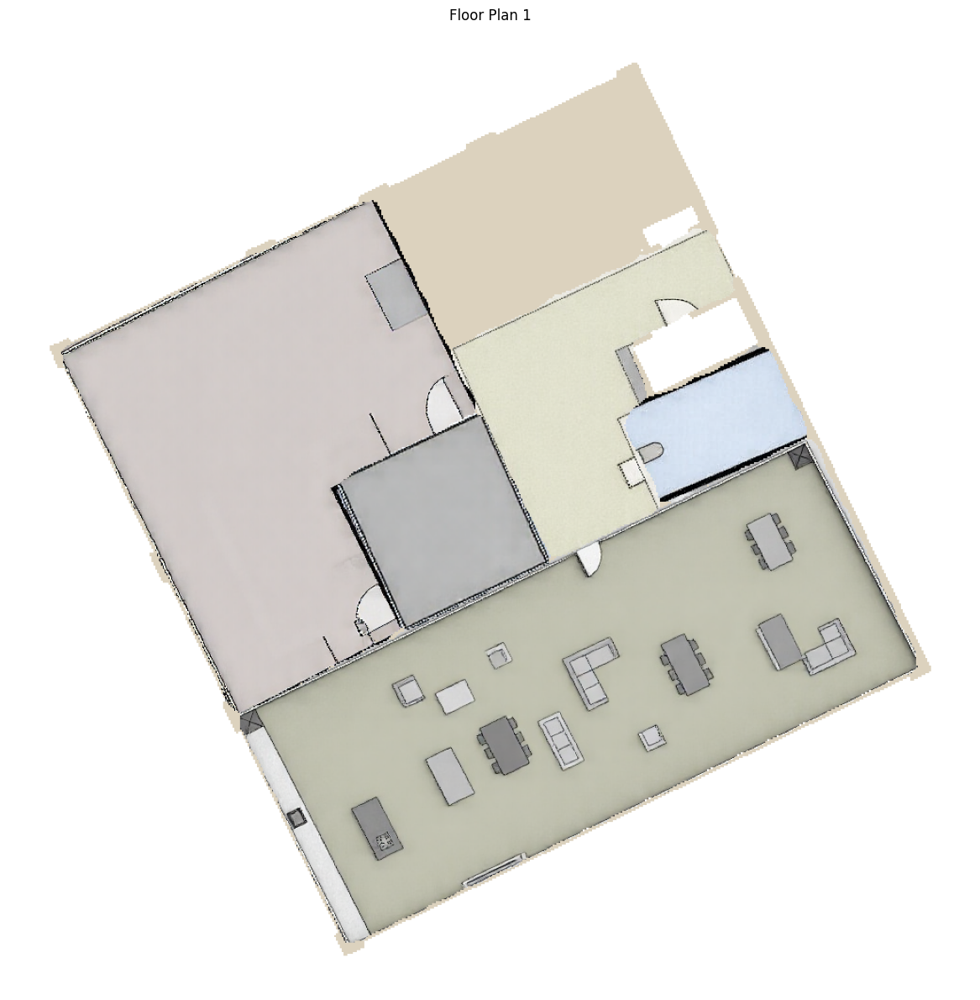

  Rooms used: living_room=00000010_living_room_1_rectangle_bottom_right_extracted_3.png, bedroom=00000010_bedroom_2_L-shaped_top_left_extracted_4.png, bathroom=00000010_bathroom_2_square_bottom_left_extracted_1.png, hallway=00000010_hallway_1_L-shaped_top_right_extracted_2.png, toilet=00000010_toilet_1_rectangle_top_right_extracted_4.png

Generating floor plan 2/15...
Found unfilled room region(s), filling with floor color...
Saved: /content/drive/MyDrive/generated/integrated_floor_plans/floor_plan_002.png


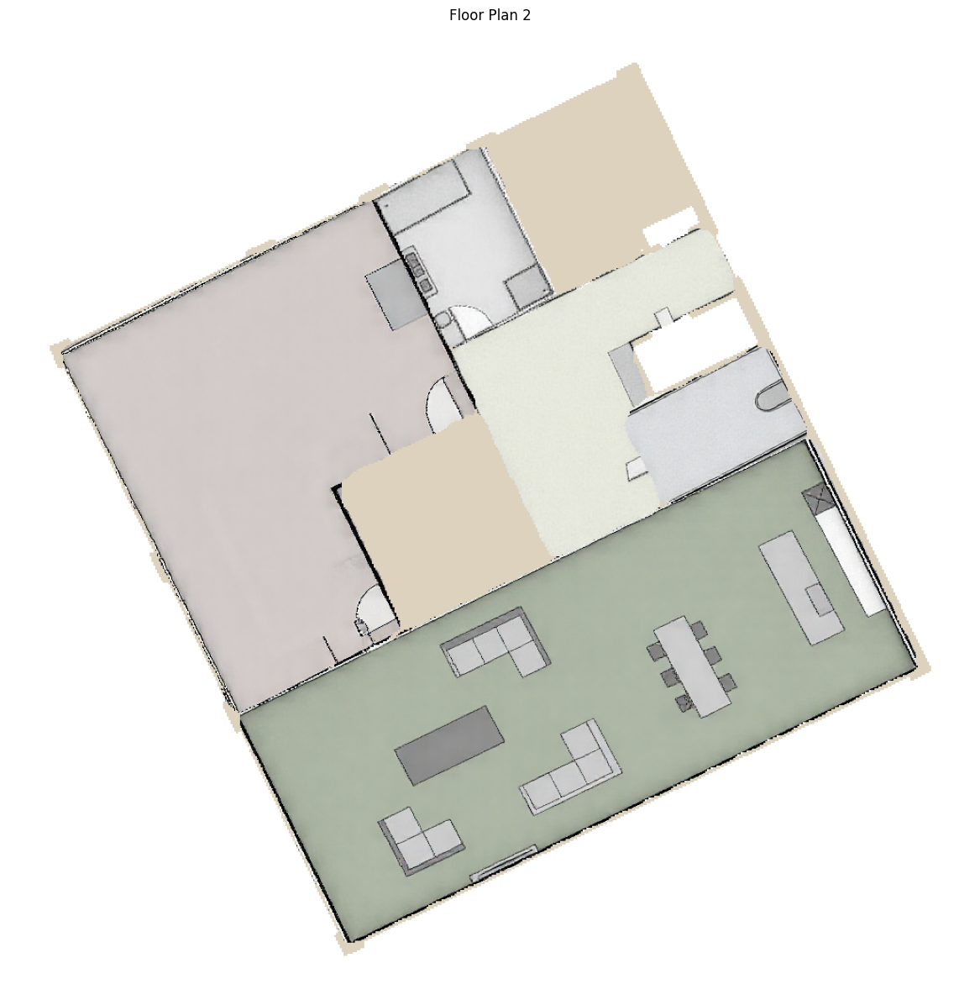

  Rooms used: living_room=00000010_living_room_1_rectangle_bottom_right_extracted_1.png, bedroom=00000010_bedroom_2_L-shaped_top_left_extracted_4.png, bathroom=00000010_bathroom_1_square_top_left_extracted_2.png, hallway=00000010_hallway_1_L-shaped_top_right_extracted_3.png, toilet=00000010_toilet_1_rectangle_top_right_extracted_2.png

Generating floor plan 3/15...
Found unfilled room region(s), filling with floor color...
Saved: /content/drive/MyDrive/generated/integrated_floor_plans/floor_plan_003.png


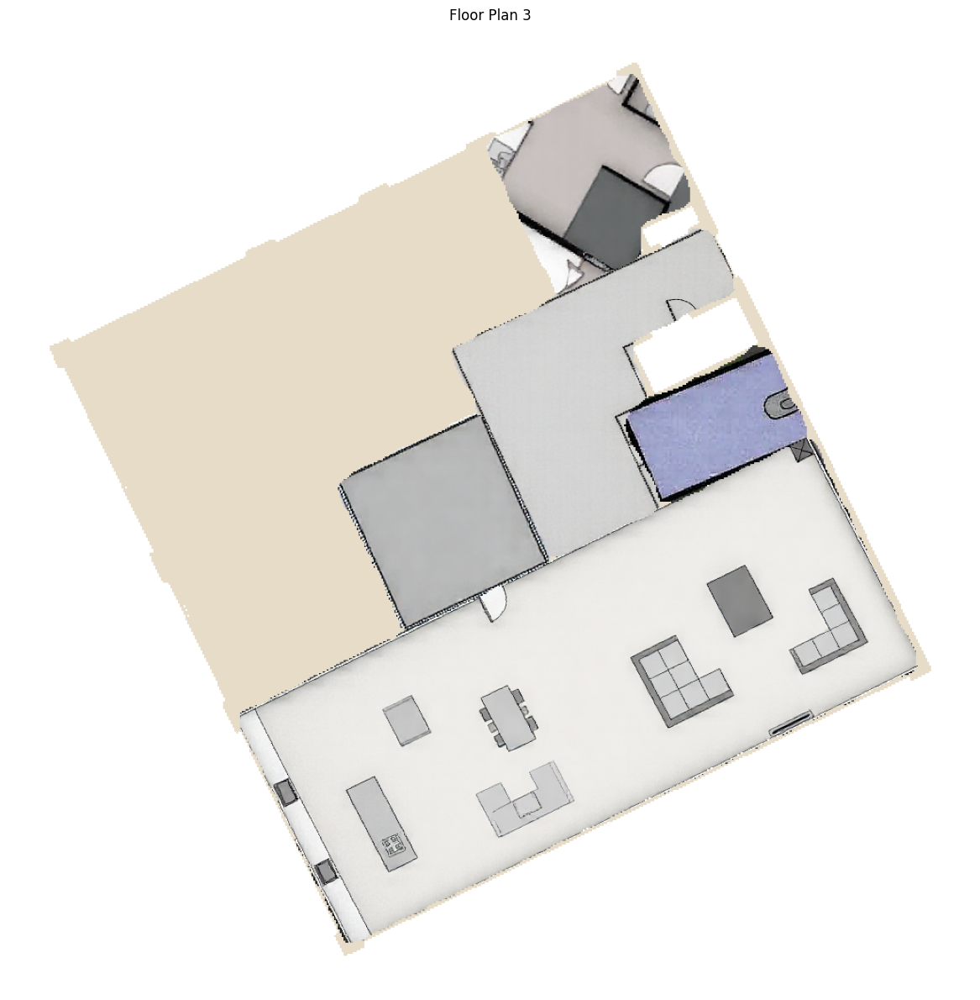

  Rooms used: living_room=00000010_living_room_1_rectangle_bottom_right_extracted_4.png, bedroom=00000010_bedroom_1_L-shaped_top_right_extracted_4.png, bathroom=00000010_bathroom_2_square_bottom_left_extracted_1.png, hallway=00000010_hallway_1_L-shaped_top_right_extracted_4.png, toilet=00000010_toilet_1_rectangle_top_right_extracted_1.png

Generating floor plan 4/15...
Found unfilled room region(s), filling with floor color...
Saved: /content/drive/MyDrive/generated/integrated_floor_plans/floor_plan_004.png


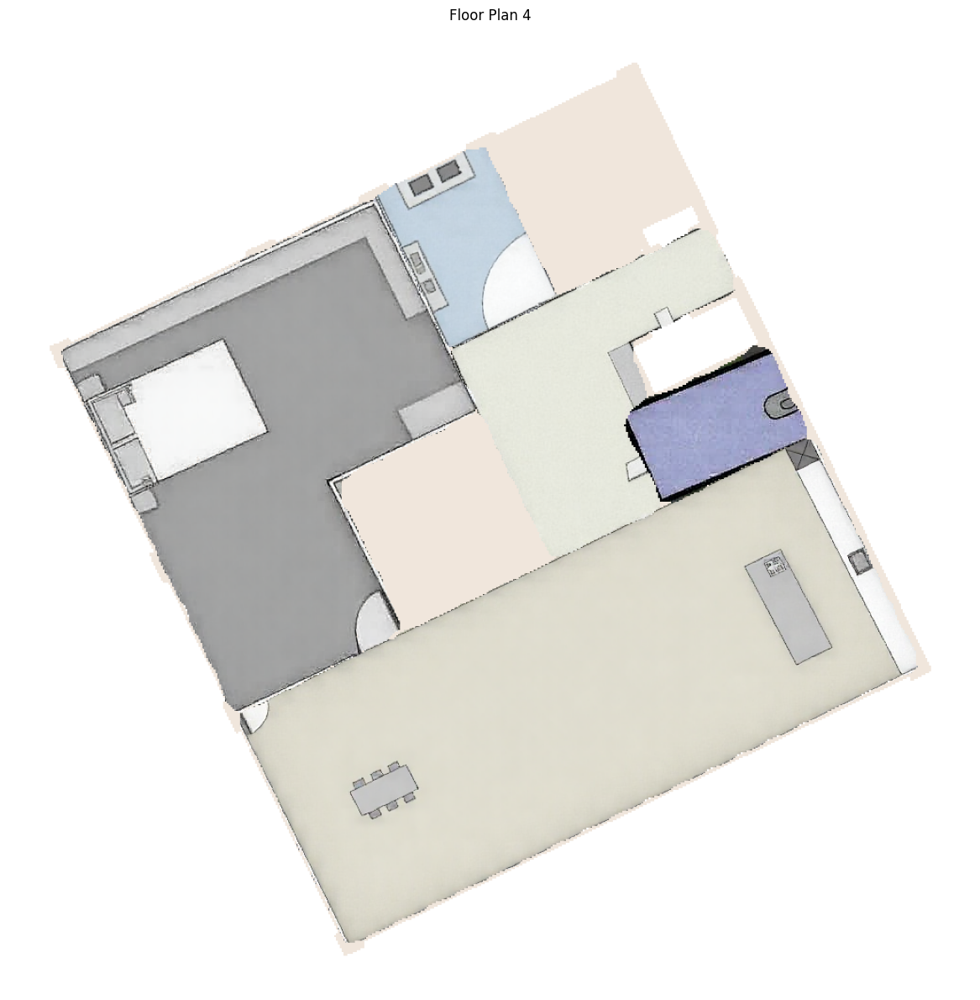

  Rooms used: living_room=00000010_living_room_1_rectangle_bottom_right_extracted_2.png, bedroom=00000010_bedroom_2_L-shaped_top_left_extracted_3.png, bathroom=00000010_bathroom_1_square_top_left_extracted_4.png, hallway=00000010_hallway_1_L-shaped_top_right_extracted_3.png, toilet=00000010_toilet_1_rectangle_top_right_extracted_1.png

Generating floor plan 5/15...
Found unfilled room region(s), filling with floor color...
Saved: /content/drive/MyDrive/generated/integrated_floor_plans/floor_plan_005.png


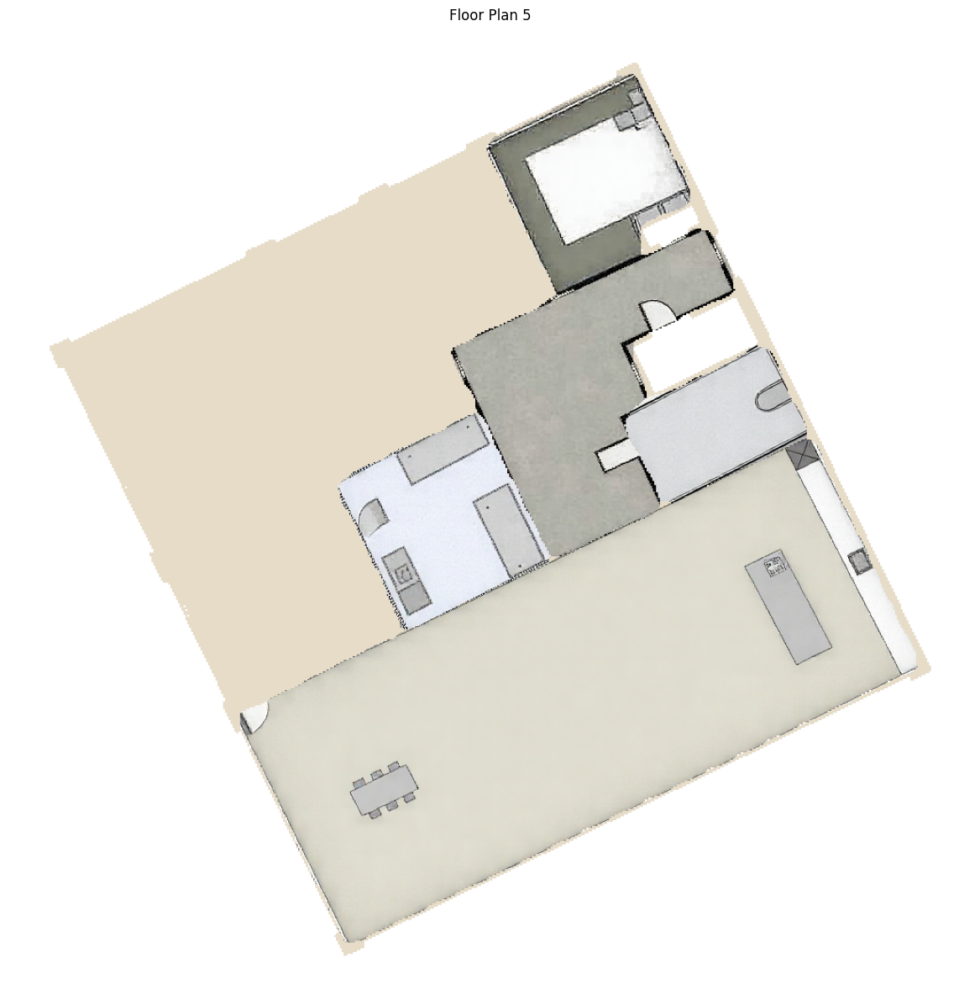

  Rooms used: living_room=00000010_living_room_1_rectangle_bottom_right_extracted_2.png, bedroom=00000010_bedroom_1_L-shaped_top_right_extracted_1.png, bathroom=00000010_bathroom_2_square_bottom_left_extracted_2.png, hallway=00000010_hallway_1_L-shaped_top_right_extracted_1.png, toilet=00000010_toilet_1_rectangle_top_right_extracted_2.png

Generating floor plan 6/15...
Found unfilled room region(s), filling with floor color...
Saved: /content/drive/MyDrive/generated/integrated_floor_plans/floor_plan_006.png


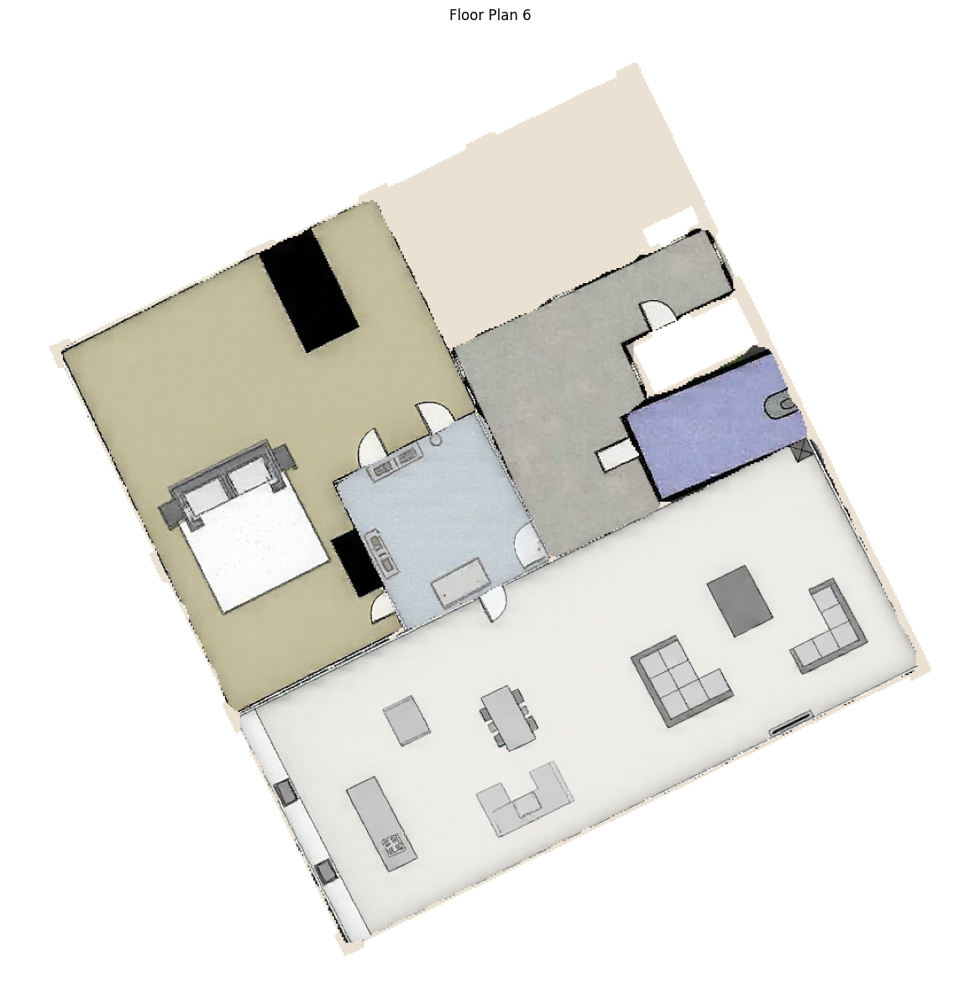

  Rooms used: living_room=00000010_living_room_1_rectangle_bottom_right_extracted_4.png, bedroom=00000010_bedroom_2_L-shaped_top_left_extracted_2.png, bathroom=00000010_bathroom_2_square_bottom_left_extracted_3.png, hallway=00000010_hallway_1_L-shaped_top_right_extracted_1.png, toilet=00000010_toilet_1_rectangle_top_right_extracted_1.png

Generating floor plan 7/15...
Found unfilled room region(s), filling with floor color...
Saved: /content/drive/MyDrive/generated/integrated_floor_plans/floor_plan_007.png


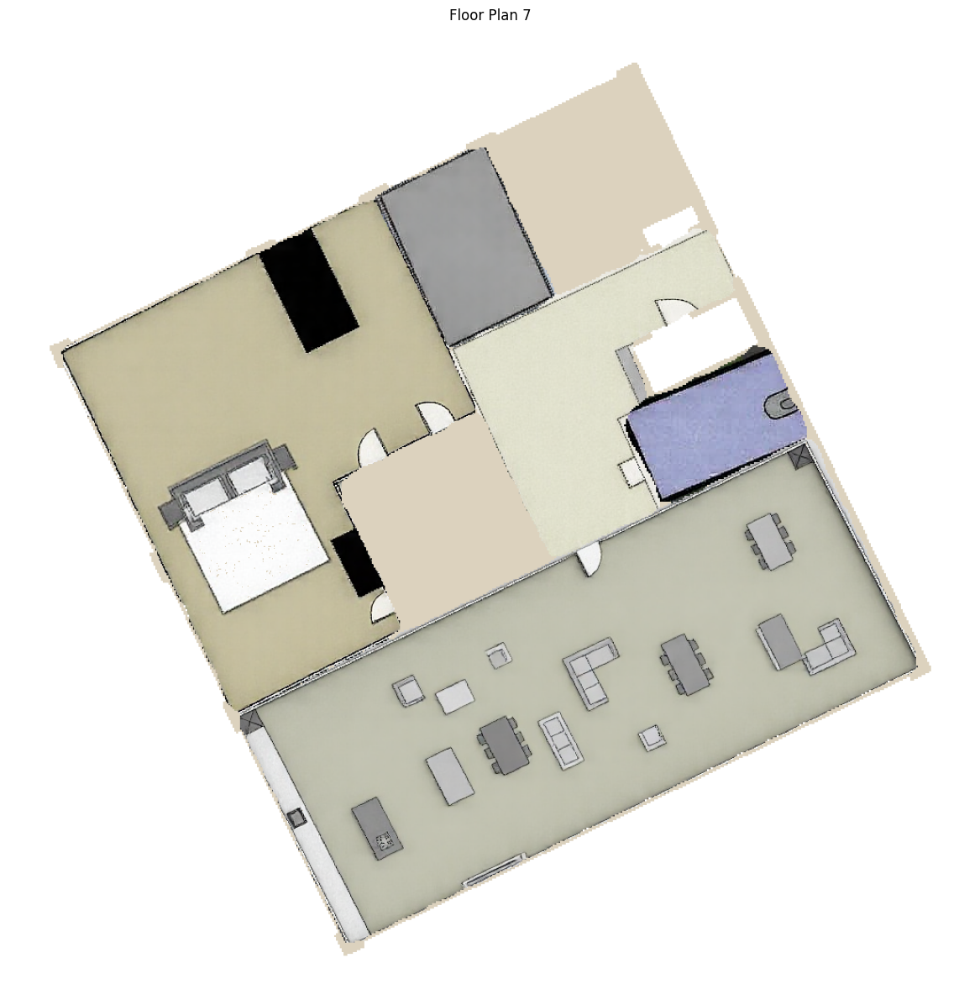

  Rooms used: living_room=00000010_living_room_1_rectangle_bottom_right_extracted_3.png, bedroom=00000010_bedroom_2_L-shaped_top_left_extracted_2.png, bathroom=00000010_bathroom_1_square_top_left_extracted_1.png, hallway=00000010_hallway_1_L-shaped_top_right_extracted_2.png, toilet=00000010_toilet_1_rectangle_top_right_extracted_1.png

Generating floor plan 8/15...
Found unfilled room region(s), filling with floor color...
Saved: /content/drive/MyDrive/generated/integrated_floor_plans/floor_plan_008.png


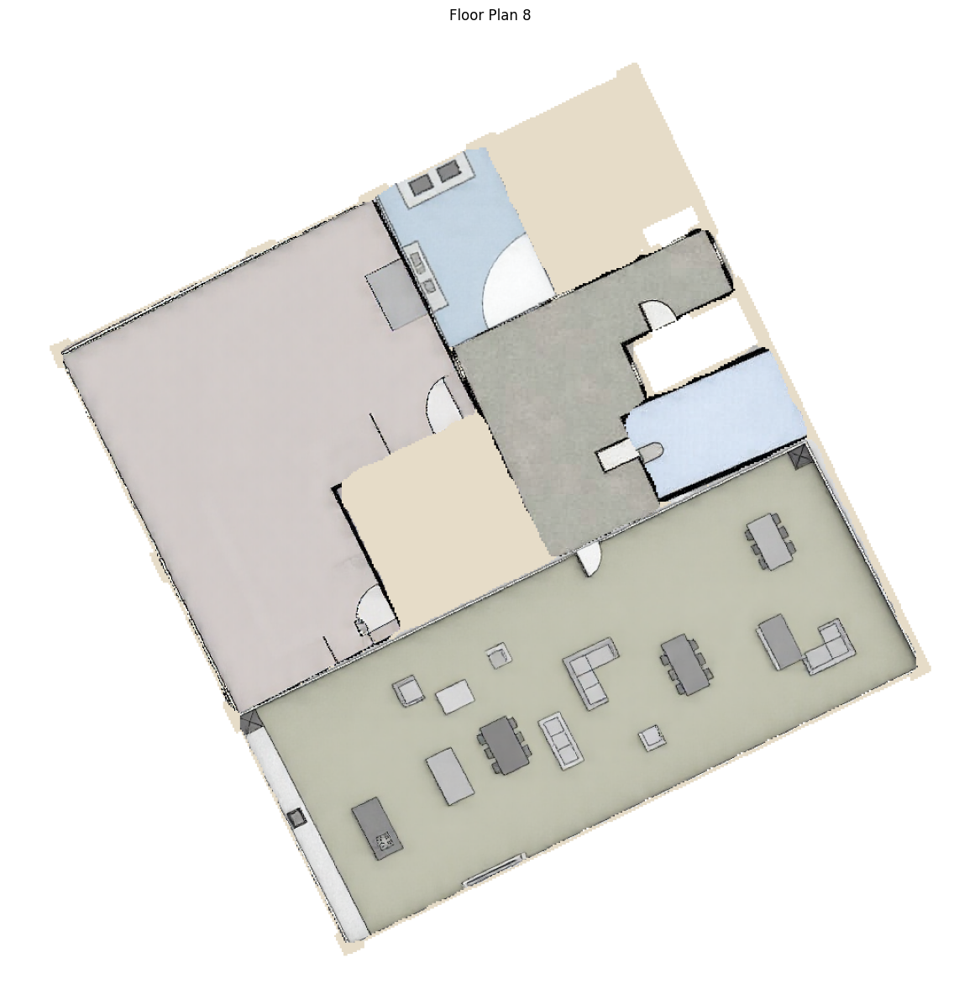

  Rooms used: living_room=00000010_living_room_1_rectangle_bottom_right_extracted_3.png, bedroom=00000010_bedroom_2_L-shaped_top_left_extracted_4.png, bathroom=00000010_bathroom_1_square_top_left_extracted_4.png, hallway=00000010_hallway_1_L-shaped_top_right_extracted_1.png, toilet=00000010_toilet_1_rectangle_top_right_extracted_4.png

Generating floor plan 9/15...
Found unfilled room region(s), filling with floor color...
Saved: /content/drive/MyDrive/generated/integrated_floor_plans/floor_plan_009.png


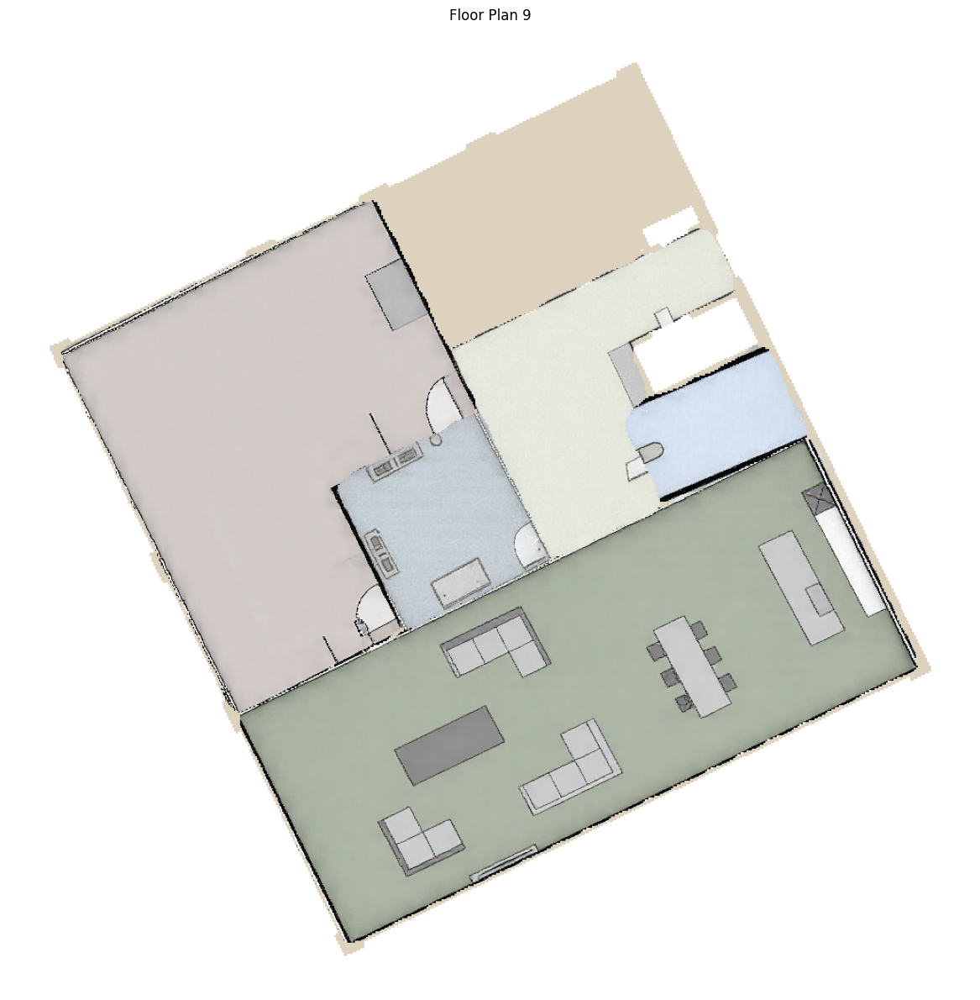

  Rooms used: living_room=00000010_living_room_1_rectangle_bottom_right_extracted_1.png, bedroom=00000010_bedroom_2_L-shaped_top_left_extracted_4.png, bathroom=00000010_bathroom_2_square_bottom_left_extracted_3.png, hallway=00000010_hallway_1_L-shaped_top_right_extracted_3.png, toilet=00000010_toilet_1_rectangle_top_right_extracted_4.png

Generating floor plan 10/15...
Found unfilled room region(s), filling with floor color...
Saved: /content/drive/MyDrive/generated/integrated_floor_plans/floor_plan_010.png


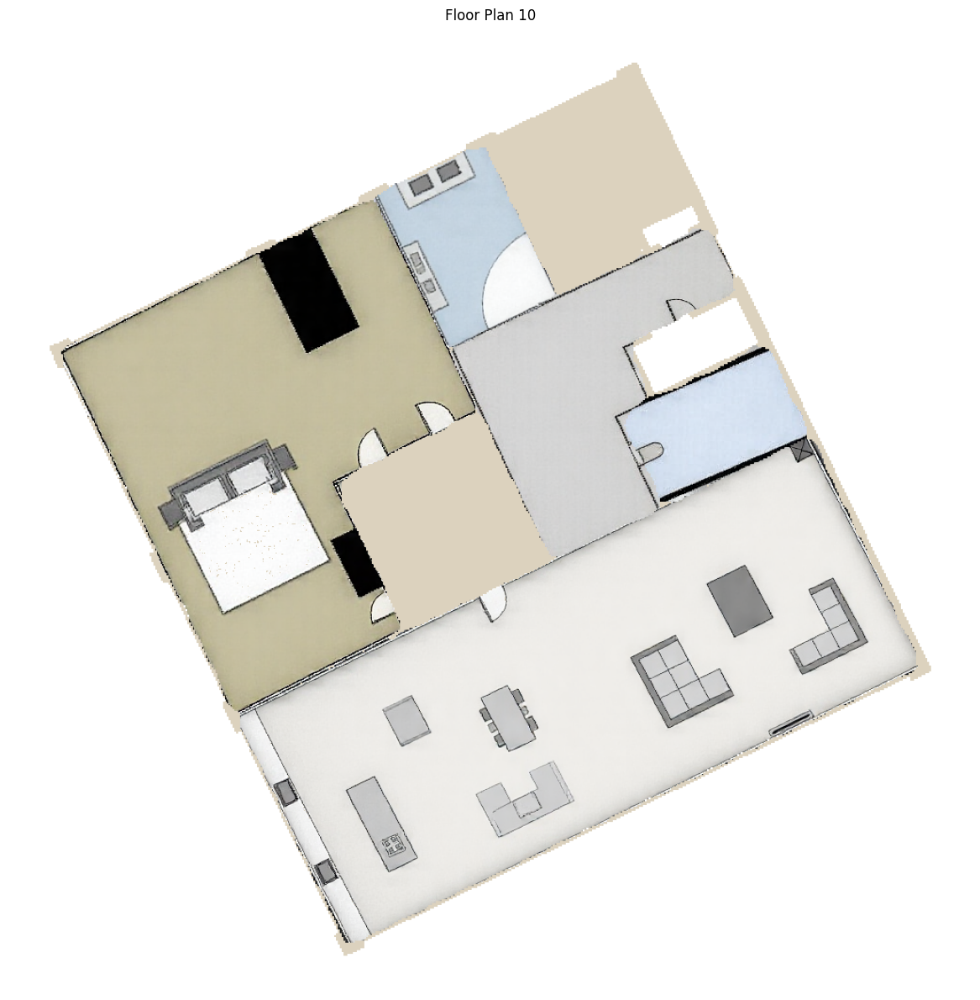

  Rooms used: living_room=00000010_living_room_1_rectangle_bottom_right_extracted_4.png, bedroom=00000010_bedroom_2_L-shaped_top_left_extracted_2.png, bathroom=00000010_bathroom_1_square_top_left_extracted_4.png, hallway=00000010_hallway_1_L-shaped_top_right_extracted_4.png, toilet=00000010_toilet_1_rectangle_top_right_extracted_4.png

Generating floor plan 11/15...
Found unfilled room region(s), filling with floor color...
Saved: /content/drive/MyDrive/generated/integrated_floor_plans/floor_plan_011.png


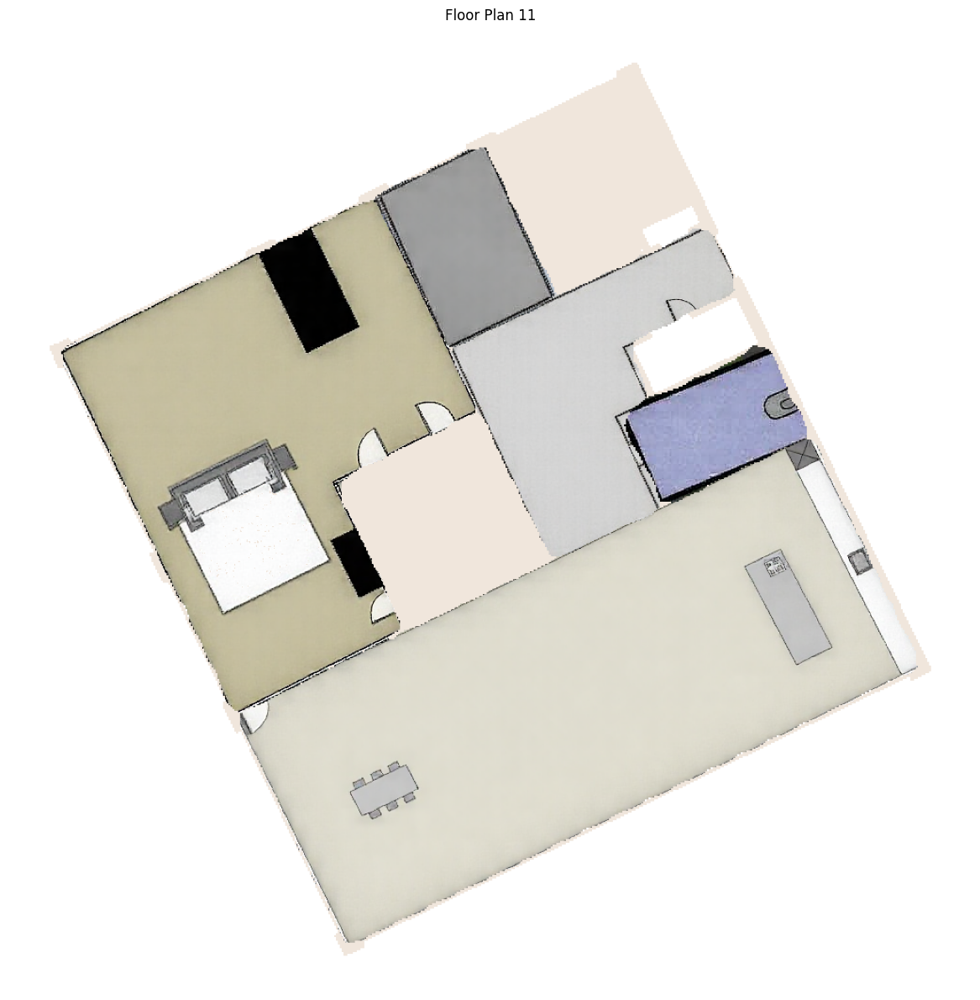

  Rooms used: living_room=00000010_living_room_1_rectangle_bottom_right_extracted_2.png, bedroom=00000010_bedroom_2_L-shaped_top_left_extracted_2.png, bathroom=00000010_bathroom_1_square_top_left_extracted_1.png, hallway=00000010_hallway_1_L-shaped_top_right_extracted_4.png, toilet=00000010_toilet_1_rectangle_top_right_extracted_1.png

Generating floor plan 12/15...
Found unfilled room region(s), filling with floor color...
Saved: /content/drive/MyDrive/generated/integrated_floor_plans/floor_plan_012.png


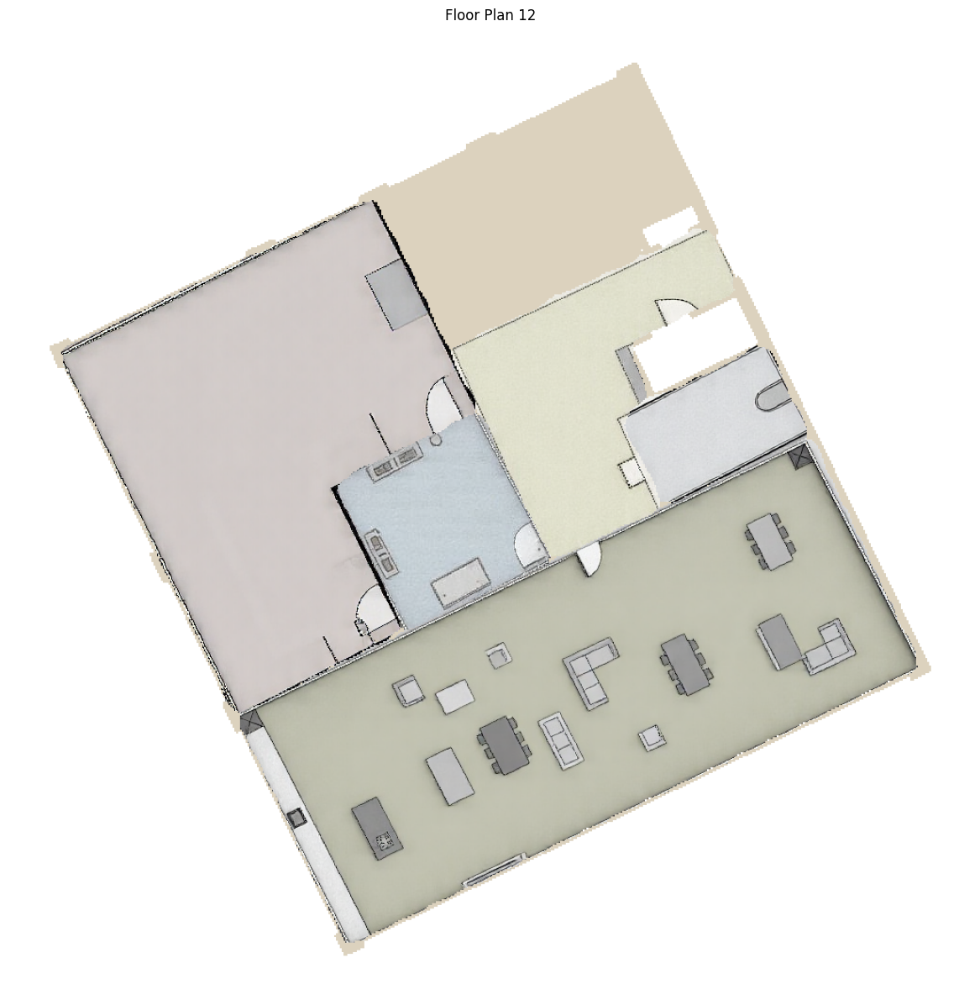

  Rooms used: living_room=00000010_living_room_1_rectangle_bottom_right_extracted_3.png, bedroom=00000010_bedroom_2_L-shaped_top_left_extracted_4.png, bathroom=00000010_bathroom_2_square_bottom_left_extracted_3.png, hallway=00000010_hallway_1_L-shaped_top_right_extracted_2.png, toilet=00000010_toilet_1_rectangle_top_right_extracted_2.png

Generating floor plan 13/15...
Found unfilled room region(s), filling with floor color...
Saved: /content/drive/MyDrive/generated/integrated_floor_plans/floor_plan_013.png


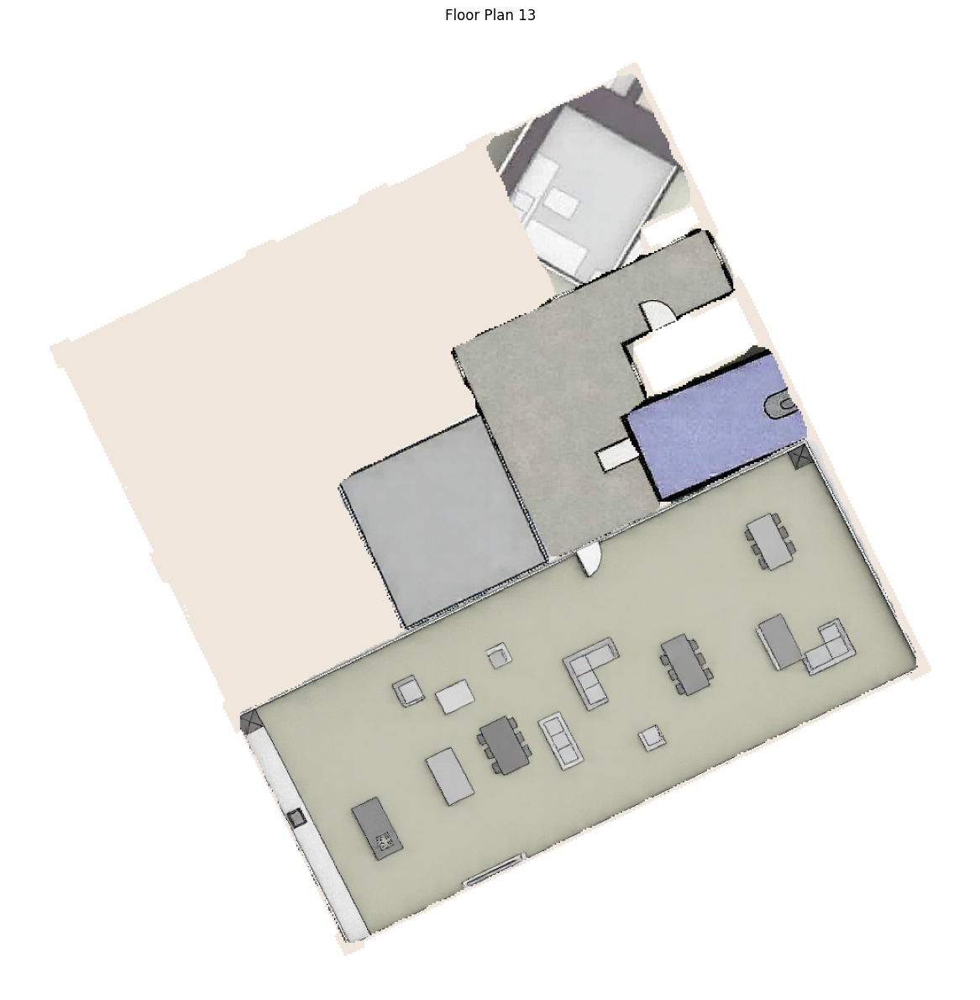

  Rooms used: living_room=00000010_living_room_1_rectangle_bottom_right_extracted_3.png, bedroom=00000010_bedroom_1_L-shaped_top_right_extracted_3.png, bathroom=00000010_bathroom_2_square_bottom_left_extracted_1.png, hallway=00000010_hallway_1_L-shaped_top_right_extracted_1.png, toilet=00000010_toilet_1_rectangle_top_right_extracted_1.png

Generating floor plan 14/15...
Found unfilled room region(s), filling with floor color...
Saved: /content/drive/MyDrive/generated/integrated_floor_plans/floor_plan_014.png


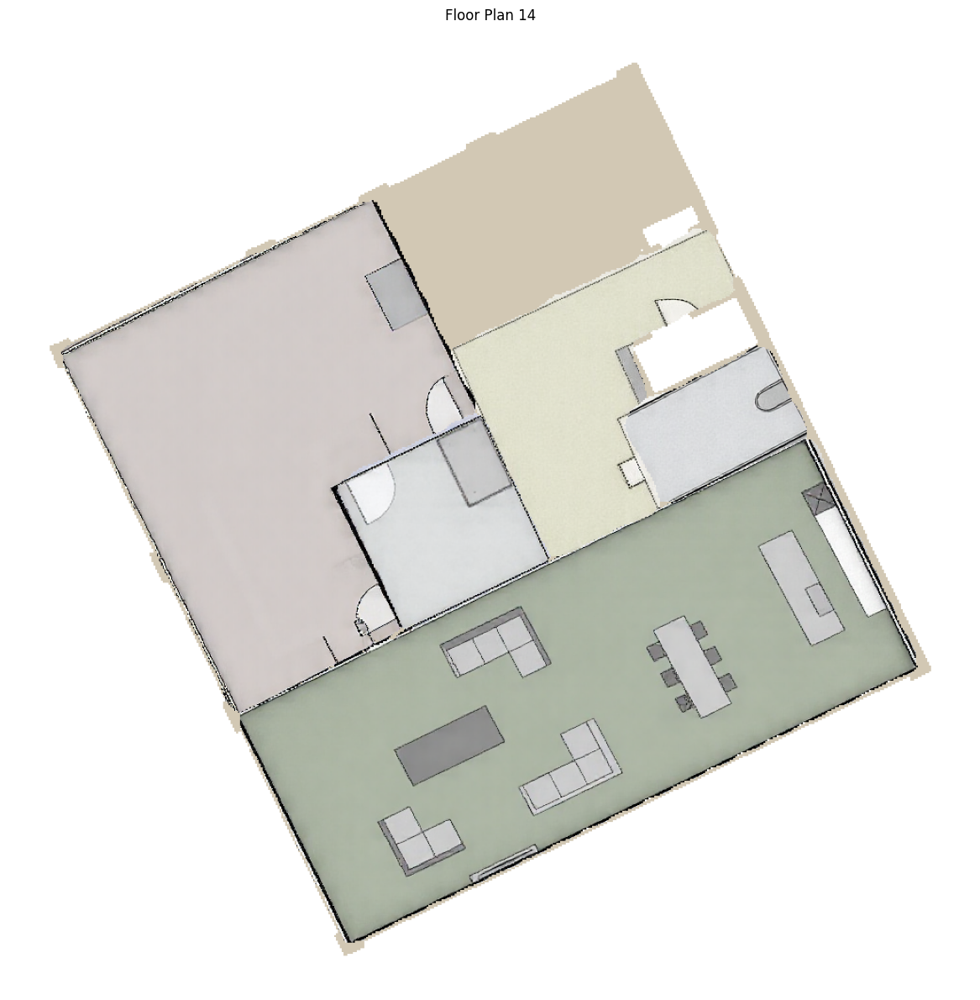

  Rooms used: living_room=00000010_living_room_1_rectangle_bottom_right_extracted_1.png, bedroom=00000010_bedroom_2_L-shaped_top_left_extracted_4.png, bathroom=00000010_bathroom_2_square_bottom_left_extracted_4.png, hallway=00000010_hallway_1_L-shaped_top_right_extracted_2.png, toilet=00000010_toilet_1_rectangle_top_right_extracted_2.png

Generating floor plan 15/15...
Found unfilled room region(s), filling with floor color...
Saved: /content/drive/MyDrive/generated/integrated_floor_plans/floor_plan_015.png


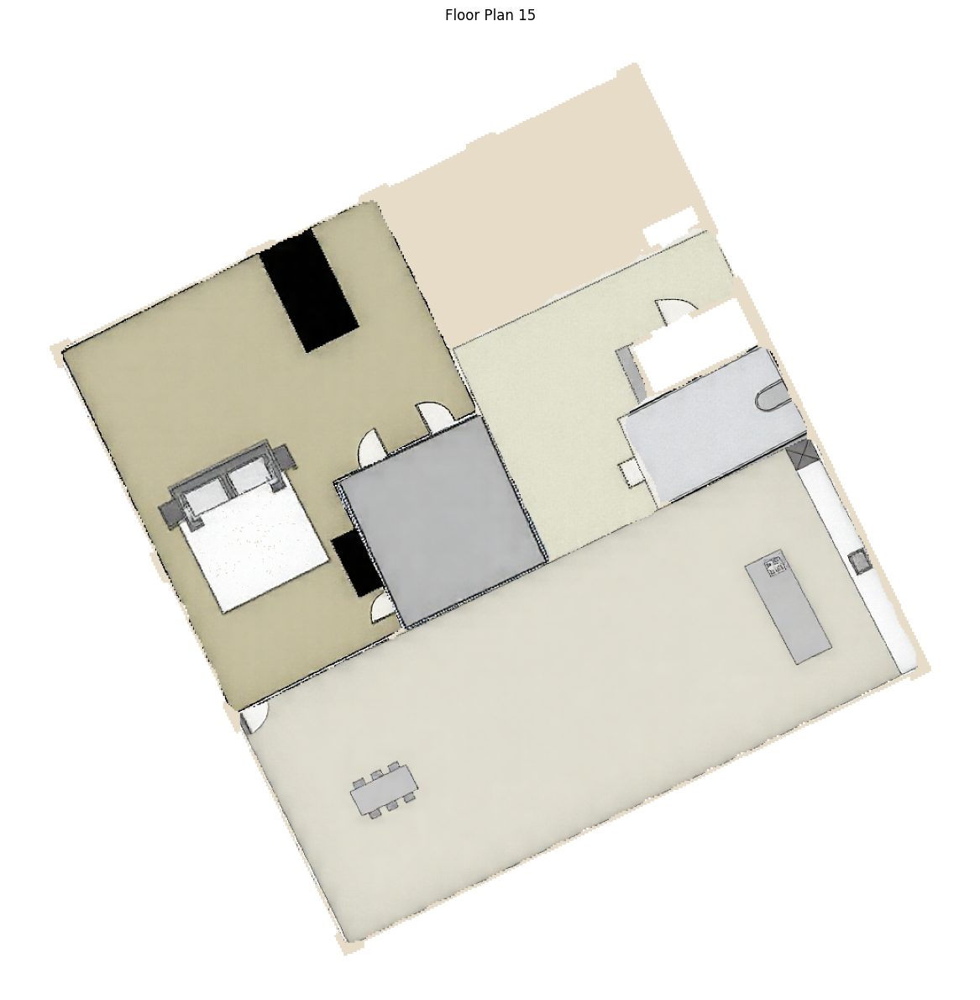

  Rooms used: living_room=00000010_living_room_1_rectangle_bottom_right_extracted_2.png, bedroom=00000010_bedroom_2_L-shaped_top_left_extracted_2.png, bathroom=00000010_bathroom_2_square_bottom_left_extracted_1.png, hallway=00000010_hallway_1_L-shaped_top_right_extracted_2.png, toilet=00000010_toilet_1_rectangle_top_right_extracted_2.png

Generated 15 floor plans successfully!

All 15 floor plans have been saved to: /content/drive/MyDrive/generated/integrated_floor_plans


In [222]:
# Set output folder for generated floor plans
output_folder = '/content/drive/MyDrive/generated/integrated_floor_plans'

# Set number of random combinations to generate (10-20 as requested)
num_combinations = 15  # You can change this to any number between 10-20

# Generate multiple random floor plans
floor_plans = generate_multiple_floor_plans(
    room_images=room_images,
    base_size=base_size,
    num_plans=num_combinations,
    output_folder=output_folder,
    segmented_mask_path=segmented_rooms  # Pass the segmented mask to fill empty rooms
)

print(f"\nAll {num_combinations} floor plans have been saved to: {output_folder}")

In [223]:
# Install required packages for furniture detection and placement
!pip install inference_sdk shapely -q
print("✓ Packages installed successfully!")

✓ Packages installed successfully!


In [224]:
# Path to floor_planrules folder in your Google Drive
floor_planrules_path = '/content/drive/MyDrive/floor_planrules'

# Path to furniture measurements JSON (from floor_planrules/furniture_crops)
furniture_json_path = '/content/drive/MyDrive/floor_planrules/furniture_crops/furniture_measurements.json'

# Add floor_planrules to Python path so we can import modules
import sys
if floor_planrules_path not in sys.path:
    sys.path.insert(0, floor_planrules_path)

print(f"✓ floor_planrules path: {floor_planrules_path}")
print(f"✓ Furniture JSON: {furniture_json_path}")

✓ floor_planrules path: /content/drive/MyDrive/floor_planrules
✓ Furniture JSON: /content/drive/MyDrive/floor_planrules/furniture_crops/furniture_measurements.json


In [225]:
from inference_sdk import InferenceHTTPClient
from typing import List, Dict, Tuple

class DetectedFurniture:
    """Represents a piece of furniture detected by YOLO"""
    def __init__(self, furniture_type: str, bbox: Tuple[int, int, int, int],
                 polygon_points: List[Tuple[int, int]], confidence: float,
                 center: Tuple[int, int], angle: float = 0):
        self.furniture_type = furniture_type
        self.bbox = bbox  # (x, y, w, h)
        self.polygon_points = polygon_points
        self.confidence = confidence
        self.center = center
        self.angle = angle

    def __repr__(self):
        return f"DetectedFurniture({self.furniture_type}, conf={self.confidence:.2f}, center={self.center})"


class FurnitureDetector:
    """Detects furniture in floor plan images using YOLO via Roboflow"""

    def __init__(self, api_key: str = None,
                 model_id: str = "furniture-ya4pe/1"):
        self.client = InferenceHTTPClient(
            api_url="https://serverless.roboflow.com",
            api_key=api_key or os.environ['ROBOFLOW_API_KEY']
        )
        self.model_id = model_id

    def detect_furniture(self, image_path: str, confidence_threshold: float = 0.3) -> List[DetectedFurniture]:
        """
        Detect furniture in an image using YOLO model.

        Parameters:
        -----------
        image_path : str
            Path to the image file
        confidence_threshold : float
            Minimum confidence score for detections

        Returns:
        --------
        List[DetectedFurniture]
            List of detected furniture items
        """
        try:
            result = self.client.infer(image_path, model_id=self.model_id)
        except Exception as e:
            print(f"  ⚠ Detection failed for {os.path.basename(image_path)}: {e}")
            return []

        detected_furniture = []

        for prediction in result.get('predictions', []):
            confidence = prediction.get('confidence', 0)
            if confidence < confidence_threshold:
                continue

            furniture_type = prediction.get('class', 'unknown')
            center_x = int(prediction.get('x', 0))
            center_y = int(prediction.get('y', 0))

            # Get polygon points if available (for segmentation models)
            polygon_points = []
            if 'points' in prediction:
                polygon_points = [(int(p['x']), int(p['y'])) for p in prediction['points']]

            # Calculate bounding box
            if polygon_points:
                xs = [p[0] for p in polygon_points]
                ys = [p[1] for p in polygon_points]
                x_min, x_max = min(xs), max(xs)
                y_min, y_max = min(ys), max(ys)
                bbox = (x_min, y_min, x_max - x_min, y_max - y_min)
            else:
                width = int(prediction.get('width', 50))
                height = int(prediction.get('height', 50))
                bbox = (center_x - width//2, center_y - height//2, width, height)

            # Calculate orientation angle from polygon
            angle = 0
            if polygon_points and len(polygon_points) >= 4:
                pts = np.array(polygon_points, dtype=np.float32)
                rect = cv2.minAreaRect(pts)
                angle = rect[2]
                # Normalize angle
                if angle < -45:
                    angle = 90 + angle
                elif angle > 45:
                    angle = angle - 90

            detected = DetectedFurniture(
                furniture_type=furniture_type,
                bbox=bbox,
                polygon_points=polygon_points,
                confidence=confidence,
                center=(center_x, center_y),
                angle=angle
            )
            detected_furniture.append(detected)

        return detected_furniture

    def detect_in_multiple_images(self, image_paths: List[str],
                                  confidence_threshold: float = 0.3) -> Dict[str, List[DetectedFurniture]]:
        """
        Detect furniture in multiple images.

        Parameters:
        -----------
        image_paths : list
            List of image file paths
        confidence_threshold : float
            Minimum confidence score

        Returns:
        --------
        dict
            Dictionary mapping image paths to lists of detected furniture
        """
        detections = {}

        for img_path in image_paths:
            print(f"  Detecting in: {os.path.basename(img_path)}")
            furniture = self.detect_furniture(img_path, confidence_threshold)
            detections[img_path] = furniture

            if furniture:
                furniture_types = [f.furniture_type for f in furniture]
                print(f"    Found {len(furniture)} items: {', '.join(furniture_types)}")
            else:
                print(f"    No furniture detected")

        return detections

print("✓ FurnitureDetector class defined with improved error handling")

✓ FurnitureDetector class defined with improved error handling


In [226]:
# Import floor_planrules modules
from room_analyzer import extract_room_dimensions, color_maps, room_types
from furniture_definitions import load_furniture_prototypes, FURNITURE_ROOM_MAP, Furniture
from furniture_placer import FurniturePlacer

print("✓ floor_planrules modules imported successfully")

# Display CORRECTED furniture-room mapping
print("\n" + "="*60)
print("CORRECTED FURNITURE-ROOM MAPPING")
print("="*60)
print("⚠️  NOTE: Original FURNITURE_ROOM_MAP has sink in living_room (WRONG)")
print("    We use CORRECTED mapping below:\n")

CORRECTED_FURNITURE_ROOM_MAP = {
    "living_room": ["Lsofa", "sofa", "tv", "table", "diningtable", "kitchen", "stove"],  # NO SINK!
    "bedroom_master": ["bed", "bedside", "study", "table"],
    "bedroom_guest": ["singlebed", "bedside", "study", "table"],
    "bedroom": ["singlebed", "bed", "bedside", "study", "table"],
    "bathroom": ["bathtub", "shower", "sink", "commode"],  # SINK ONLY HERE
    "toilet": ["commode", "sink"],  # AND HERE
    "hallway": [],
    "empty_room": [],
}

for room_type, furniture_list in CORRECTED_FURNITURE_ROOM_MAP.items():
    if furniture_list:
        print(f"  {room_type}:")
        print(f"    → {', '.join(furniture_list)}")
    else:
        print(f"  {room_type}: (empty)")
print("="*60)

✓ floor_planrules modules imported successfully

CORRECTED FURNITURE-ROOM MAPPING
⚠️  NOTE: Original FURNITURE_ROOM_MAP has sink in living_room (WRONG)
    We use CORRECTED mapping below:

  living_room:
    → Lsofa, sofa, tv, table, diningtable, kitchen, stove
  bedroom_master:
    → bed, bedside, study, table
  bedroom_guest:
    → singlebed, bedside, study, table
  bedroom:
    → singlebed, bed, bedside, study, table
  bathroom:
    → bathtub, shower, sink, commode
  toilet:
    → commode, sink
  hallway: (empty)
  empty_room: (empty)


In [227]:
import copy

class FurnitureMapper:
    """Maps YOLO-detected furniture to floor_planrules furniture format"""

    # Mapping from YOLO class names to floor_planrules furniture types
    YOLO_TO_FLOORPLAN_MAP = {
        'bed': 'bed',
        'single_bed': 'singlebed',
        'singlebed': 'singlebed',
        'sofa': 'sofa',
        'l_sofa': 'Lsofa',
        'L-sofa': 'Lsofa',
        'l-sofa': 'Lsofa',
        'Lsofa': 'Lsofa',
        'tv': 'tv',
        'table': 'table',
        'dining_table': 'diningtable',
        'diningtable': 'diningtable',
        'bathtub': 'bathtub',
        'shower': 'shower',
        'sink': 'sink',
        'commode': 'commode',
        'toilet': 'commode',
        'bedside': 'bedside',
        'study': 'study',
        'study_table': 'study',
        'desk': 'study',
        'kitchen': 'kitchen',
        'stove': 'stove',
        'door': 'door',
        'chair': 'chair',
    }

    # CORRECTED: Strict room-furniture mapping
    # IMPORTANT: sink is ONLY in bathroom/toilet, NOT in living_room
    ROOM_TYPE_FURNITURE_MAP = {
        "living_room": ["Lsofa", "sofa", "tv", "table", "diningtable", "kitchen", "stove"],  # NO sink!
        "bedroom": ["bed", "singlebed", "bedside", "study", "table"],
        "bedroom_master": ["bed", "bedside", "study", "table"],
        "bedroom_guest": ["singlebed", "bedside", "study", "table"],
        "bathroom": ["bathtub", "shower", "sink", "commode"],  # sink belongs HERE
        "toilet": ["commode", "sink"],  # and HERE
        "hallway": [],
        "empty_room": [],
    }

    def __init__(self, pixel_to_meter_ratio: float = 0.1, furniture_prototypes=None):
        self.pixel_to_meter_ratio = pixel_to_meter_ratio
        self.furniture_prototypes = furniture_prototypes or {}

    def map_furniture_type(self, yolo_type: str) -> str:
        """Map YOLO furniture type to floor_planrules type"""
        yolo_type_clean = yolo_type.lower().strip().replace(' ', '_').replace('-', '')

        # Direct match first
        if yolo_type_clean in self.YOLO_TO_FLOORPLAN_MAP:
            return self.YOLO_TO_FLOORPLAN_MAP[yolo_type_clean]

        # Try with original format (for L-sofa, etc.)
        yolo_original = yolo_type.lower().strip()
        if yolo_original in self.YOLO_TO_FLOORPLAN_MAP:
            return self.YOLO_TO_FLOORPLAN_MAP[yolo_original]

        # Try partial matching
        for yolo_key, floorplan_type in self.YOLO_TO_FLOORPLAN_MAP.items():
            if yolo_key in yolo_type_clean or yolo_type_clean in yolo_key:
                return floorplan_type

        print(f"  Warning: Unknown furniture type '{yolo_type}', will be skipped")
        return None  # Return None for unknown types

    def _get_room_base_type(self, room_name: str) -> str:
        """
        Extract the base room type from room name.
        E.g., 'bedroom_1' -> 'bedroom', 'living_room_2' -> 'living_room'
        """
        room_name_lower = room_name.lower()

        # Check for compound room types first (living_room before just room)
        compound_types = ['living_room', 'bedroom_master', 'bedroom_guest', 'empty_room']
        for compound in compound_types:
            if room_name_lower.startswith(compound):
                return compound

        # Simple extraction - take first part before underscore with number
        parts = room_name_lower.split('_')
        if len(parts) >= 2 and parts[-1].isdigit():
            # Remove the trailing number
            return '_'.join(parts[:-1])

        # Handle cases like 'bedroom1'
        import re
        match = re.match(r'^([a-z_]+?)(\d+)?$', room_name_lower)
        if match:
            return match.group(1).rstrip('_')

        return room_name_lower

    def furniture_belongs_to_room(self, furniture_name: str, room_name: str) -> bool:
        """
        STRICT check if a furniture type is appropriate for a given room.
        Uses room BASE TYPE for matching (bedroom_1 -> bedroom)
        """
        if furniture_name is None:
            return False

        # Get the base room type
        room_type = self._get_room_base_type(room_name)

        # Get valid furniture for this room type from our STRICT map
        valid_furniture = self.ROOM_TYPE_FURNITURE_MAP.get(room_type, [])

        # Normalize furniture name for comparison
        furniture_name_lower = furniture_name.lower()

        # STRICT matching - must be in the valid list
        for valid_type in valid_furniture:
            valid_type_lower = valid_type.lower()
            if furniture_name_lower == valid_type_lower:
                return True
            # Allow partial match only for compound names (e.g., singlebed matches bed)
            if furniture_name_lower in valid_type_lower or valid_type_lower in furniture_name_lower:
                return True

        return False

    def get_furniture_dimensions_from_json(self, furniture_type: str):
        """
        Get furniture dimensions from JSON prototypes instead of YOLO bbox.
        """
        if furniture_type is None:
            return None, None

        furniture_type_lower = furniture_type.lower()

        # Look for matching furniture in prototypes
        if furniture_type in self.furniture_prototypes and self.furniture_prototypes[furniture_type]:
            prototype = self.furniture_prototypes[furniture_type][0]
            return prototype.width_m, prototype.height_m

        # Try partial matching with various patterns
        for proto_type, proto_list in self.furniture_prototypes.items():
            if proto_list:
                proto_type_lower = proto_type.lower()
                if (furniture_type_lower in proto_type_lower or
                    proto_type_lower in furniture_type_lower or
                    furniture_type_lower.replace('_', '') == proto_type_lower.replace('_', '')):
                    return proto_list[0].width_m, proto_list[0].height_m

        return None, None

    def convert_to_furniture_object(self, detected: DetectedFurniture,
                                   original_filename: str = None) -> Furniture:
        """Convert DetectedFurniture to Furniture object with JSON dimensions"""
        mapped_type = self.map_furniture_type(detected.furniture_type)

        if mapped_type is None:
            return None  # Skip unknown furniture types

        # Use JSON dimensions for consistent sizing
        width_m, height_m = self.get_furniture_dimensions_from_json(mapped_type)

        if width_m is None or height_m is None:
            # Fallback to YOLO dimensions if not found in JSON
            bbox_width_px = detected.bbox[2]
            bbox_height_px = detected.bbox[3]
            width_m = bbox_width_px * self.pixel_to_meter_ratio
            height_m = bbox_height_px * self.pixel_to_meter_ratio
            print(f"  ⚠ Using YOLO dimensions for {mapped_type}: {width_m:.2f}m x {height_m:.2f}m")
        else:
            print(f"  ✓ Using JSON dimensions for {mapped_type}: {width_m:.2f}m x {height_m:.2f}m")

        if original_filename is None:
            original_filename = f"{detected.furniture_type}.png"

        # Create Furniture object
        furniture = Furniture(
            name=mapped_type,
            width_m=width_m,
            height_m=height_m,
            original_filename=original_filename
        )

        # Store detected position info for placement hints
        furniture.detected_position_px = detected.center
        furniture.detected_angle = detected.angle
        furniture.detected_bbox = detected.bbox
        furniture.confidence = detected.confidence
        furniture.is_from_detection = True

        # Convert dimensions to pixels
        furniture.width_px = width_m / self.pixel_to_meter_ratio
        furniture.height_px = height_m / self.pixel_to_meter_ratio

        return furniture

    def group_by_room_with_validation(self, detections_by_image: Dict[str, List[DetectedFurniture]]) -> tuple:
        """
        Convert and group detected furniture by room, STRICTLY validating furniture belongs to room type.
        Removes any furniture that doesn't belong in its detected room.
        """
        valid_furniture_by_room = {}
        invalid_furniture_by_room = {}

        for img_path, detected_list in detections_by_image.items():
            filename = os.path.basename(img_path)
            room_instance = self._extract_room_instance(filename)
            room_type = self._get_room_base_type(room_instance)

            print(f"\nProcessing {filename} -> Room: {room_instance} (type: {room_type})")

            for i, detected in enumerate(detected_list):
                furniture = self.convert_to_furniture_object(
                    detected,
                    original_filename=f"{i}_{detected.furniture_type}.png"
                )

                # Skip if furniture type is unknown
                if furniture is None:
                    print(f"    ✗ Skipping unknown type: {detected.furniture_type}")
                    continue

                # STRICT validation: Check if this furniture belongs in this room type
                if self.furniture_belongs_to_room(furniture.name, room_instance):
                    if room_instance not in valid_furniture_by_room:
                        valid_furniture_by_room[room_instance] = []
                    valid_furniture_by_room[room_instance].append(furniture)
                    print(f"    ✓ {furniture.name} is valid for {room_type}")
                else:
                    if room_instance not in invalid_furniture_by_room:
                        invalid_furniture_by_room[room_instance] = []
                    invalid_furniture_by_room[room_instance].append(furniture)
                    print(f"    ✗ REJECTED: {furniture.name} does NOT belong in {room_type}")

        return valid_furniture_by_room, invalid_furniture_by_room

    def _extract_room_instance(self, filename: str) -> str:
        """Extract room instance identifier from filename"""
        name = filename.replace('.png', '').replace('.jpg', '').replace('_extracted', '')
        parts = name.split('_')

        # Check for compound room types
        if len(parts) >= 2 and parts[0] == 'living' and parts[1] == 'room':
            if len(parts) >= 3 and parts[2].isdigit():
                return f"living_room_{parts[2]}"
            return "living_room"

        # Simple room types with number
        if len(parts) >= 2 and parts[1].isdigit():
            return f"{parts[0]}_{parts[1]}"

        return parts[0]

    def group_by_room(self, detections_by_image: Dict[str, List[DetectedFurniture]]) -> Dict[str, List[Furniture]]:
        """Convert and group detected furniture by room (backward compatibility)"""
        valid_furniture, _ = self.group_by_room_with_validation(detections_by_image)
        return valid_furniture

print("✓ FurnitureMapper class defined with STRICT room-furniture validation")
print("  - Sink is ONLY allowed in bathroom/toilet (removed from living_room)")
print("  - Unknown furniture types are skipped")
print("  - Strict validation removes hallucinations")

✓ FurnitureMapper class defined with STRICT room-furniture validation
  - Sink is ONLY allowed in bathroom/toilet (removed from living_room)
  - Unknown furniture types are skipped
  - Strict validation removes hallucinations


In [228]:
from shapely.geometry import Polygon, Point
from shapely.affinity import rotate as shapely_rotate, translate as shapely_translate
import copy

# CORRECTED FURNITURE MAP - sink NOT in living room!
CORRECTED_FURNITURE_ROOM_MAP = {
    "living_room": ["Lsofa", "sofa", "tv", "table", "diningtable", "kitchen", "stove"],
    "bedroom_master": ["bed", "bedside", "study", "table"],
    "bedroom_guest": ["singlebed", "bedside", "study", "table"],
    "bedroom": ["singlebed", "bed", "bedside", "study", "table"],
    "bathroom": ["bathtub", "shower", "sink", "commode"],
    "toilet": ["commode", "sink"],
    "hallway": [],
    "empty_room": [],
}

# Maximum allowed instances of each furniture type per room
# (e.g., only 1 bed, 1 sofa, but up to 2 bedside tables)
MAX_FURNITURE_PER_ROOM = {
    "bed": 1,
    "singlebed": 1,
    "Lsofa": 1,
    "sofa": 1,
    "tv": 1,
    "diningtable": 1,
    "table": 1,
    "kitchen": 1,
    "stove": 1,
    "bathtub": 1,
    "shower": 1,
    "sink": 1,
    "commode": 1,
    "bedside": 2,  # Can have 2 bedside tables
    "study": 1,
}

class EnhancedFurniturePlacer(FurniturePlacer):
    """
    Enhanced placer that combines detected furniture from LoRA/YOLO with rule-based placement.

    KEY FEATURES:
    1. Uses detected positions as hints but validates them against interior design rules
    2. Strict boundary checking - furniture must be FULLY inside room polygons
    3. No overlaps - maintains global list of placed furniture polygons
    4. ALWAYS fills empty rooms with appropriate furniture from prototypes
    5. Creates FRESH COPIES of prototypes for each room (never consumes originals)
    6. LIMITS each furniture type to MAX instances per room (no duplicates)
    """

    def __init__(self, rooms_info, furniture_prototypes, furniture_map, pixel_to_meter_ratio,
                 detected_furniture_by_room=None, use_detected_positions=True,
                 position_tolerance=50, debug=False, min_wall_distance=5):
        # Store original prototypes BEFORE parent init modifies them
        self.original_prototypes = {}
        for name, proto_list in furniture_prototypes.items():
            self.original_prototypes[name] = []
            for proto in proto_list:
                # Deep copy each prototype
                proto_copy = Furniture(
                    name=proto.name,
                    width_m=proto.width_m,
                    height_m=proto.height_m,
                    original_filename=proto.original_filename
                )
                proto_copy.width_px = proto.width_m / pixel_to_meter_ratio
                proto_copy.height_px = proto.height_m / pixel_to_meter_ratio
                self.original_prototypes[name].append(proto_copy)

        # Use CORRECTED furniture map
        super().__init__(rooms_info, furniture_prototypes, CORRECTED_FURNITURE_ROOM_MAP, pixel_to_meter_ratio, debug)
        self.detected_furniture_by_room = detected_furniture_by_room or {}
        self.use_detected_positions = use_detected_positions
        self.position_tolerance = position_tolerance
        self.min_wall_distance = min_wall_distance

        # Global tracking of ALL placed furniture across rooms
        self.global_placed_polygons = []

    def _get_room_base_type(self, room_name: str) -> str:
        """Extract base room type from room name (e.g., 'bedroom_1' -> 'bedroom')"""
        import re
        room_name_lower = room_name.lower()

        compound_types = ['living_room', 'bedroom_master', 'bedroom_guest', 'empty_room']
        for compound in compound_types:
            if room_name_lower.startswith(compound):
                return compound

        match = re.match(r'^([a-z_]+?)_?\d*$', room_name_lower)
        if match:
            return match.group(1).rstrip('_')

        return room_name_lower

    def _get_furniture_polygon(self, furniture, center_pos, angle):
        """Creates a shapely Polygon for a furniture item."""
        w, h = furniture.width_px, furniture.height_px
        corners = [(-w/2, -h/2), (w/2, -h/2), (w/2, h/2), (-w/2, h/2)]
        poly = Polygon(corners)
        poly = shapely_rotate(poly, angle, origin='center', use_radians=False)
        poly = shapely_translate(poly, xoff=center_pos[0], yoff=center_pos[1])
        return poly

    def _check_valid_placement(self, furniture_poly, room_polygon, placed_polygons, buffer_margin=2.0):
        """STRICT placement validation."""
        # Check for collisions with local furniture
        for placed_poly in placed_polygons:
            if furniture_poly.intersects(placed_poly):
                return False

        # Check for collisions with globally placed furniture
        for global_poly in self.global_placed_polygons:
            if furniture_poly.intersects(global_poly):
                return False

        # STRICT: Entire furniture must be inside room
        if room_polygon.contains(furniture_poly):
            return True

        # Allow slight buffer for edge placements
        if room_polygon.buffer(buffer_margin).contains(furniture_poly):
            return True

        return False

    def _try_place_at_detected_position(self, furniture, room_polygon, placed_polygons):
        """Try to place furniture at or near its detected position."""
        if not hasattr(furniture, 'detected_position_px') or furniture.detected_position_px is None:
            return False, None

        detected_pos = np.array(furniture.detected_position_px)
        detected_angle = getattr(furniture, 'detected_angle', 0)

        if self.debug:
            print(f"    Trying detected position for {furniture.name}: {detected_pos}")

        # Try exact detected position first
        poly = self._get_furniture_polygon(furniture, detected_pos, detected_angle)
        if self._check_valid_placement(poly, room_polygon, placed_polygons):
            furniture.position_px = (int(detected_pos[0]), int(detected_pos[1]))
            furniture.angle = detected_angle
            if self.debug:
                print(f"    ✓ Placed at exact detected position")
            return True, poly

        # Try adjustments around detected position
        search_angles = [detected_angle, detected_angle + 90, detected_angle - 90, detected_angle + 180]
        search_offsets = [
            (self.position_tolerance, 0), (-self.position_tolerance, 0),
            (0, self.position_tolerance), (0, -self.position_tolerance),
            (self.position_tolerance/2, self.position_tolerance/2),
            (-self.position_tolerance/2, -self.position_tolerance/2),
        ]

        for angle in search_angles:
            for offset in search_offsets:
                adjusted_pos = detected_pos + np.array(offset)
                poly = self._get_furniture_polygon(furniture, adjusted_pos, angle)

                if self._check_valid_placement(poly, room_polygon, placed_polygons):
                    furniture.position_px = (int(adjusted_pos[0]), int(adjusted_pos[1]))
                    furniture.angle = angle
                    if self.debug:
                        print(f"    ✓ Placed at adjusted position")
                    return True, poly

        if self.debug:
            print(f"    ✗ Could not place near detected position")
        return False, None

    def _place_with_wall_rules(self, furniture, room_data, room_polygon, placed_polygons):
        """Place furniture using wall-based rules from floor_planrules."""
        walls = self._get_walls(room_data['bounding_box'])
        walls.sort(key=lambda w: np.linalg.norm(w[1] - w[0]), reverse=True)

        orientations = [(furniture.width_px, furniture.height_px)]
        if furniture.width_px != furniture.height_px:
            orientations.append((furniture.height_px, furniture.width_px))

        for wall in walls:
            wall_vec = wall[1] - wall[0]
            wall_len = np.linalg.norm(wall_vec)
            wall_angle = np.rad2deg(np.arctan2(wall_vec[1], wall_vec[0]))

            for f_w, f_h in orientations:
                if f_w > wall_len * 0.9:
                    continue

                orig_w, orig_h = furniture.width_px, furniture.height_px
                furniture.width_px, furniture.height_px = f_w, f_h

                for t in [0.5, 0.3, 0.7, 0.2, 0.8, 0.15, 0.85, 0.1, 0.9]:
                    pos = wall[0] + wall_vec * t
                    normal = self._get_wall_normal(pos, room_polygon, wall_vec)
                    pos_adjusted = pos + normal * (f_h / 2 + self.min_wall_distance)

                    poly = self._get_furniture_polygon(furniture, pos_adjusted, wall_angle)

                    if self._check_valid_placement(poly, room_polygon, placed_polygons):
                        furniture.position_px = (int(pos_adjusted[0]), int(pos_adjusted[1]))
                        furniture.angle = wall_angle
                        if self.debug:
                            print(f"    ✓ Placed against wall at {t*100:.0f}%")
                        return True, poly

                furniture.width_px, furniture.height_px = orig_w, orig_h

        return False, None

    def _get_wall_normal(self, point, room_polygon, wall_vec):
        """Gets a normal vector pointing into the room from a wall."""
        normal = np.array([-wall_vec[1], wall_vec[0]])
        norm_val = np.linalg.norm(normal)
        if norm_val > 0:
            normal = normal / norm_val

        centroid = np.array(room_polygon.centroid.coords[0])
        vec_to_centroid = centroid - point
        if np.dot(normal, vec_to_centroid) < 0:
            normal = -normal
        return normal

    def _create_fresh_prototype(self, furniture_type):
        """
        Create a FRESH COPY of a furniture prototype.
        This ensures we never run out of furniture for rooms.
        """
        # Try exact match first
        if furniture_type in self.original_prototypes and self.original_prototypes[furniture_type]:
            proto = self.original_prototypes[furniture_type][0]
            furniture_copy = Furniture(
                name=proto.name,
                width_m=proto.width_m,
                height_m=proto.height_m,
                original_filename=proto.original_filename
            )
            furniture_copy.width_px = proto.width_px
            furniture_copy.height_px = proto.height_px
            furniture_copy.is_from_detection = False
            return furniture_copy

        # Try case-insensitive match
        furniture_type_lower = furniture_type.lower()
        for proto_key, proto_list in self.original_prototypes.items():
            if proto_list and proto_key.lower() == furniture_type_lower:
                proto = proto_list[0]
                furniture_copy = Furniture(
                    name=proto.name,
                    width_m=proto.width_m,
                    height_m=proto.height_m,
                    original_filename=proto.original_filename
                )
                furniture_copy.width_px = proto.width_px
                furniture_copy.height_px = proto.height_px
                furniture_copy.is_from_detection = False
                return furniture_copy

        return None

    def _get_normalized_furniture_type(self, furniture_name):
        """
        Get normalized furniture type for counting purposes.
        E.g., 'bed', 'Bed', 'BED' all map to 'bed'
        IMPORTANT: All furniture types must be mapped here for deduplication to work!
        """
        name_lower = furniture_name.lower().strip()

        # Direct mapping for ALL furniture types - order matters (check specific before general)
        type_mappings = {
            # Bathroom/Toilet items
            'sink': 'sink',
            'commode': 'commode',
            'toilet': 'commode',
            'bathtub': 'bathtub',
            'shower': 'shower',
            # Bedroom items
            'singlebed': 'singlebed',
            'single_bed': 'singlebed',
            'bedside': 'bedside',
            'study': 'study',
            'desk': 'study',
            # Living room items
            'lsofa': 'sofa',
            'l-sofa': 'sofa',
            'l_sofa': 'sofa',
            'sofa': 'sofa',
            'tv': 'tv',
            'television': 'tv',
            'diningtable': 'diningtable',
            'dining_table': 'diningtable',
            'kitchen': 'kitchen',
            'stove': 'stove',
            'table': 'table',
            # Must check 'bed' AFTER 'singlebed' and 'bedside'
            'bed': 'bed',
        }

        # Check each mapping - use exact substring match
        for key, canonical in type_mappings.items():
            if key in name_lower:
                return canonical

        # Default: return the lowercase name itself
        return name_lower

    def _deduplicate_detected_furniture(self, detected_items):
        """
        Remove duplicate detections of the same furniture type.
        Keep only the highest confidence detection for each type.
        """
        if not detected_items:
            return []

        # Group by normalized type
        by_type = {}
        for item in detected_items:
            norm_type = self._get_normalized_furniture_type(item.name)
            if norm_type not in by_type:
                by_type[norm_type] = []
            by_type[norm_type].append(item)

        # Debug: show what we grouped
        if self.debug:
            print(f"    Grouping detected furniture by type:")
            for norm_type, items in by_type.items():
                print(f"      {norm_type}: {len(items)} items")

        # Keep only the best (highest confidence) for each type, up to MAX limit
        deduplicated = []
        for norm_type, items in by_type.items():
            max_allowed = MAX_FURNITURE_PER_ROOM.get(norm_type, 1)

            # Sort by confidence (highest first)
            items.sort(key=lambda f: getattr(f, 'confidence', 0.5), reverse=True)

            # Take only up to max_allowed
            selected = items[:max_allowed]
            deduplicated.extend(selected)

            # Always log when we reduce items
            if len(items) > max_allowed:
                print(f"    ⚠ DEDUP {norm_type}: keeping {max_allowed} of {len(items)} (removed {len(items) - max_allowed} duplicates)")

        return deduplicated

    def _get_furniture_for_room(self, room_name, room_type):
        """
        Get furniture for a room: deduplicated detected + FRESH rule-based prototypes.
        LIMITS each furniture type to MAX instances per room.
        """
        detected_items = []

        # Match detected furniture to this room
        # Use a scoring system to find the best match
        for detected_room, furniture_list in self.detected_furniture_by_room.items():
            detected_room_lower = detected_room.lower()
            room_name_lower = room_name.lower()

            # Score matching: exact match = 100, same base type with number = 50, same type = 10
            match_score = 0

            if detected_room_lower == room_name_lower:
                match_score = 100  # Exact match
            elif detected_room_lower.startswith(room_name_lower.split('_')[0]) and \
                 room_name_lower.startswith(detected_room_lower.split('_')[0]):
                # Check if they have same instance number or one doesn't have a number
                detected_parts = detected_room_lower.replace('_', ' ').split()
                room_parts = room_name_lower.replace('_', ' ').split()

                detected_nums = [p for p in detected_parts if p.isdigit()]
                room_nums = [p for p in room_parts if p.isdigit()]

                if detected_nums == room_nums:
                    match_score = 80  # Same instance number
                elif not detected_nums or not room_nums:
                    match_score = 60  # One has no number

            if match_score >= 60:
                detected_items.extend(furniture_list)
                if self.debug:
                    print(f"  Matched {len(furniture_list)} items from '{detected_room}' to '{room_name}' (score: {match_score})")

        # DEDUPLICATE detected items - keep only best of each type
        # This is critical to prevent multiple sinks, beds, etc.
        if detected_items:
            original_count = len(detected_items)
            print(f"  Before deduplication: {original_count} items")
            for item in detected_items:
                norm_type = self._get_normalized_furniture_type(item.name)
                conf = getattr(item, 'confidence', 0.5)
                print(f"    - {item.name} → normalized: '{norm_type}' (conf: {conf})")

            detected_items = self._deduplicate_detected_furniture(detected_items)

            print(f"  After deduplication: {len(detected_items)} items")
            if len(detected_items) < original_count:
                print(f"  ✓ Removed {original_count - len(detected_items)} duplicate(s)")

        # Track what furniture types we already have (and their counts)
        detected_type_counts = {}
        for f in detected_items:
            norm_type = self._get_normalized_furniture_type(f.name)
            detected_type_counts[norm_type] = detected_type_counts.get(norm_type, 0) + 1

        # Get FRESH prototypes only for types we don't have enough of
        prototype_items = []
        furniture_needed = self.furniture_map.get(room_type, [])

        if self.debug:
            print(f"  Room type '{room_type}' needs: {furniture_needed}")

        for f_type in furniture_needed:
            norm_type = self._get_normalized_furniture_type(f_type)
            current_count = detected_type_counts.get(norm_type, 0)
            max_allowed = MAX_FURNITURE_PER_ROOM.get(norm_type, 1)

            # Skip if we already have enough of this type
            if current_count >= max_allowed:
                if self.debug:
                    print(f"    Skipping {f_type} - already have {current_count}/{max_allowed}")
                continue

            # Create a FRESH COPY of the prototype
            furniture_copy = self._create_fresh_prototype(f_type)
            if furniture_copy:
                prototype_items.append(furniture_copy)
                # Update count so we don't add more than allowed
                detected_type_counts[norm_type] = current_count + 1
                if self.debug:
                    print(f"    Added FRESH prototype: {f_type}")
            else:
                if self.debug:
                    print(f"    ⚠ No prototype found for: {f_type}")

        all_items = detected_items + prototype_items

        if self.debug:
            print(f"  Total for {room_name}: {len(detected_items)} detected + {len(prototype_items)} prototypes = {len(all_items)}")

        return all_items

    def _place_in_room(self, room_data):
        """Place furniture in a single room with rule-based placement."""
        room_type = room_data['type']

        room_name = None
        for name, data in self.rooms_info.items():
            if data is room_data:
                room_name = name
                break

        if room_name is None:
            room_name = f"{room_type}_unknown"

        if self.debug:
            print(f"\n{'='*60}")
            print(f"PLACING FURNITURE IN: {room_name} (type: {room_type})")
            print(f"{'='*60}")

        # Create room polygon
        if room_data.get('contour') is not None and len(room_data['contour']) > 2:
            room_polygon = Polygon(np.squeeze(room_data['contour']))
        else:
            room_polygon = Polygon(room_data['bounding_box'])

        if not room_polygon.is_valid:
            room_polygon = room_polygon.buffer(0)

        # Get furniture for this room (already deduplicated)
        furniture_to_place = self._get_furniture_for_room(room_name, room_type)

        if not furniture_to_place:
            if self.debug:
                print(f"  ⚠ No furniture available for {room_type}")
            return []

        placed_in_this_room = []
        placed_polygons = []

        # Track placed furniture types to enforce limits during placement
        placed_type_counts = {}

        # Separate and sort
        detected_furniture = [f for f in furniture_to_place if getattr(f, 'is_from_detection', False)]
        prototype_furniture = [f for f in furniture_to_place if not getattr(f, 'is_from_detection', False)]

        detected_furniture.sort(key=lambda f: (getattr(f, 'confidence', 0.5), f.width_px * f.height_px), reverse=True)
        prototype_furniture.sort(key=lambda f: f.width_px * f.height_px, reverse=True)

        # Initialize stats for this room type
        if room_type not in self.placement_stats:
            self.placement_stats[room_type] = {'attempted': 0, 'placed': 0, 'failed': 0}

        def can_place_type(furniture_name):
            """Check if we can place another of this furniture type."""
            norm_type = self._get_normalized_furniture_type(furniture_name)
            current = placed_type_counts.get(norm_type, 0)
            max_allowed = MAX_FURNITURE_PER_ROOM.get(norm_type, 1)
            return current < max_allowed

        def record_placed(furniture_name):
            """Record that we placed this furniture type."""
            norm_type = self._get_normalized_furniture_type(furniture_name)
            placed_type_counts[norm_type] = placed_type_counts.get(norm_type, 0) + 1

        # Place detected furniture first
        if self.debug and detected_furniture:
            print(f"\n  --- Placing {len(detected_furniture)} detected items ---")

        for furniture in detected_furniture:
            # Check if we already have enough of this type
            if not can_place_type(furniture.name):
                if self.debug:
                    print(f"  ⚠ Skipping {furniture.name} - already placed max allowed")
                continue

            self.placement_stats[room_type]['attempted'] += 1

            if self.debug:
                print(f"\n  Placing detected: {furniture.name}")

            if self.use_detected_positions:
                success, poly = self._try_place_at_detected_position(furniture, room_polygon, placed_polygons)
                if success:
                    placed_in_this_room.append(furniture)
                    placed_polygons.append(poly)
                    self.global_placed_polygons.append(poly)
                    self.placement_stats[room_type]['placed'] += 1
                    record_placed(furniture.name)
                    continue

            success, poly = self._place_with_wall_rules(furniture, room_data, room_polygon, placed_polygons)
            if success:
                placed_in_this_room.append(furniture)
                placed_polygons.append(poly)
                self.global_placed_polygons.append(poly)
                self.placement_stats[room_type]['placed'] += 1
                record_placed(furniture.name)
            else:
                self.placement_stats[room_type]['failed'] += 1
                if self.debug:
                    print(f"    ✗ Could not place {furniture.name}")

        # Place prototype furniture (rule-based)
        if self.debug and prototype_furniture:
            print(f"\n  --- Placing {len(prototype_furniture)} rule-based items ---")

        for furniture in prototype_furniture:
            # Check if we already have enough of this type
            if not can_place_type(furniture.name):
                if self.debug:
                    print(f"  ⚠ Skipping {furniture.name} - already placed max allowed")
                continue

            self.placement_stats[room_type]['attempted'] += 1

            if self.debug:
                print(f"\n  Placing prototype: {furniture.name}")

            success, poly = self._place_with_wall_rules(furniture, room_data, room_polygon, placed_polygons)
            if success:
                placed_in_this_room.append(furniture)
                placed_polygons.append(poly)
                self.global_placed_polygons.append(poly)
                self.placement_stats[room_type]['placed'] += 1
                record_placed(furniture.name)
            else:
                self.placement_stats[room_type]['failed'] += 1
                if self.debug:
                    print(f"    ✗ Could not place {furniture.name}")

        if self.debug:
            detected_count = sum(1 for f in placed_in_this_room if getattr(f, 'is_from_detection', False))
            rule_count = len(placed_in_this_room) - detected_count
            print(f"\n  SUMMARY: Placed {len(placed_in_this_room)} items ({detected_count} detected + {rule_count} rule-based)")

        return placed_in_this_room

    def place_all(self):
        """Place furniture in all rooms."""
        # Initialize placement stats
        for room_data in self.rooms_info.values():
            room_type = room_data['type']
            if room_type not in self.placement_stats:
                self.placement_stats[room_type] = {'attempted': 0, 'placed': 0, 'failed': 0}

        self.global_placed_polygons = []

        for room_name, room_data in self.rooms_info.items():
            self.placed_furniture[room_name] = self._place_in_room(room_data)

        if self.debug:
            print("\n" + "="*60)
            print("PLACEMENT STATISTICS")
            print("="*60)
            total_placed = 0
            total_attempted = 0
            for room_type, stats in self.placement_stats.items():
                if stats['attempted'] > 0:
                    success_rate = stats['placed'] / stats['attempted'] * 100
                    print(f"{room_type}: {stats['placed']}/{stats['attempted']} ({success_rate:.1f}%)")
                    total_placed += stats['placed']
                    total_attempted += stats['attempted']

            if total_attempted > 0:
                print(f"\nTOTAL: {total_placed}/{total_attempted} ({total_placed/total_attempted*100:.1f}%)")

        return self.placed_furniture

print("✓ EnhancedFurniturePlacer defined with:")
print("  - CORRECTED furniture-room mapping (sink NOT in living_room)")
print("  - Creates FRESH COPIES of prototypes (never runs out)")
print("  - DEDUPLICATES multiple detections of same furniture type")
print("  - LIMITS each furniture type to MAX per room (no adjacent duplicates)")
print("  - Strict boundary and overlap checking")
print("\nMAX furniture per room:")
for f_type, max_count in MAX_FURNITURE_PER_ROOM.items():
    print(f"  {f_type}: {max_count}")

✓ EnhancedFurniturePlacer defined with:
  - CORRECTED furniture-room mapping (sink NOT in living_room)
  - Creates FRESH COPIES of prototypes (never runs out)
  - DEDUPLICATES multiple detections of same furniture type
  - LIMITS each furniture type to MAX per room (no adjacent duplicates)
  - Strict boundary and overlap checking

MAX furniture per room:
  bed: 1
  singlebed: 1
  Lsofa: 1
  sofa: 1
  tv: 1
  diningtable: 1
  table: 1
  kitchen: 1
  stove: 1
  bathtub: 1
  shower: 1
  sink: 1
  commode: 1
  bedside: 2
  study: 1


In [ ]:
def generate_floor_plan_with_optimal_furniture(
    lora_room_images,
    segmented_mask_path,
    furniture_json_path,
    output_folder,
    pixel_to_meter_ratio=0.1,
    confidence_threshold=0.3,
    debug=True,
    variation_id=None,
    furniture_crops_path=None,
    all_lora_room_images=None
):
    """
    Complete workflow: LoRA output -> YOLO detection -> STRICT Validation -> Rule-Based Placement

    FIXES APPLIED:
    - Sink is ONLY placed in bathroom/toilet (NOT living room)
    - Empty rooms are ALWAYS filled with rule-based furniture (FRESH copies)
    - Hallucinated/wrong furniture is removed before placement
    """

    variation_str = f" (Variation {variation_id})" if variation_id else ""

    print("="*80)
    print(f"FLOOR PLAN FURNITURE PLACEMENT{variation_str}")
    print("="*80)

    # =========================================================================
    # STEP 1: Detect furniture from LoRA outputs
    # =========================================================================
    print("\n" + "="*80)
    print("STEP 1: Detecting furniture from LoRA outputs using YOLO")
    print("="*80)

    detector = FurnitureDetector()
    detections = detector.detect_in_multiple_images(lora_room_images, confidence_threshold)

    total_detected = sum(len(d) for d in detections.values())
    print(f"\n✓ Total furniture detected: {total_detected}")

    # =========================================================================
    # STEP 2: Load furniture prototypes (FRESH for each run)
    # =========================================================================
    print("\n" + "="*80)
    print("STEP 2: Loading furniture prototypes")
    print("="*80)

    furniture_prototypes = load_furniture_prototypes(furniture_json_path)

    for name in furniture_prototypes:
        for f_item in furniture_prototypes[name]:
            f_item.width_px = f_item.width_m / pixel_to_meter_ratio
            f_item.height_px = f_item.height_m / pixel_to_meter_ratio

    total_prototypes = sum(len(items) for items in furniture_prototypes.values())
    print(f"✓ Loaded {total_prototypes} furniture prototypes")
    print(f"  Types: {', '.join(sorted(furniture_prototypes.keys()))}")

    # =========================================================================
    # STEP 3: STRICT validation - remove wrong furniture from rooms
    # =========================================================================
    print("\n" + "="*80)
    print("STEP 3: STRICT validation - re:moving wrong furniture from rooms")
    print("="*80)

    mapper = FurnitureMapper(pixel_to_meter_ratio, furniture_prototypes)
    valid_furniture_by_room, invalid_furniture_by_room = mapper.group_by_room_with_validation(detections)

    valid_count = sum(len(f) for f in valid_furniture_by_room.values())
    invalid_count = sum(len(f) for f in invalid_furniture_by_room.values())

    print(f"\n✓ VALID furniture: {valid_count}")
    print(f"✗ REJECTED furniture (wrong room): {invalid_count}")

    # =========================================================================
    # STEP 4: Analyze room structure
    # =========================================================================
    print("\n" + "="*80)
    print("STEP 4: Analyzing room structure from segmented mask")
    print("="*80)

    segmented_image = cv2.imread(segmented_mask_path)
    if segmented_image is None:
        raise ValueError(f"Could not load segmented image: {segmented_mask_path}")
    segmented_image = cv2.cvtColor(segmented_image, cv2.COLOR_BGR2RGB)

    rooms_info = extract_room_dimensions(segmented_image, color_maps, room_types, pixel_to_meter_ratio)

    print(f"\n✓ Found {len(rooms_info)} rooms:")
    for room_name, room_data in rooms_info.items():
        print(f"  • {room_name} ({room_data['type']}): {room_data['area_units']:.1f} m²")

    # =========================================================================
    # STEP 5: Place furniture with rule-based logic
    # =========================================================================
    print("\n" + "="*80)
    print("STEP 5: Placing furniture (detected + rule-based to fill ALL rooms)")
    print("="*80)

    placer = EnhancedFurniturePlacer(
        rooms_info=rooms_info,
        furniture_prototypes=furniture_prototypes,
        furniture_map=CORRECTED_FURNITURE_ROOM_MAP,
        pixel_to_meter_ratio=pixel_to_meter_ratio,
        detected_furniture_by_room=valid_furniture_by_room,
        use_detected_positions=True,
        position_tolerance=50,
        debug=debug,
        min_wall_distance=5
    )

    final_layout = placer.place_all()

    # =========================================================================
    # STEP 6: Summary
    # =========================================================================
    print("\n" + "="*80)
    print("PLACEMENT SUMMARY")
    print("="*80)

    total_placed = 0
    empty_rooms = []

    for room_name, furniture_list in final_layout.items():
        count = len(furniture_list)
        total_placed += count

        if count == 0:
            empty_rooms.append(room_name)
            room_type = rooms_info[room_name]['type']
            if room_type in ['hallway', 'empty_room']:
                print(f"⬜ {room_name}: Empty (expected for hallway)")
            else:
                print(f"❌ {room_name}: EMPTY!")
        else:
            detected_count = sum(1 for f in furniture_list if getattr(f, 'is_from_detection', False))
            rule_count = count - detected_count
            furniture_names = [f.name for f in furniture_list]
            print(f"✓ {room_name}: {count} items ({detected_count} detected + {rule_count} rule-based)")
            print(f"    → {', '.join(furniture_names)}")

    print(f"\n{'='*40}")
    print(f"TOTAL FURNITURE PLACED: {total_placed}")

    # =========================================================================
    # STEP 7: Visualization
    # =========================================================================
    print("\n" + "="*80)
    print("STEP 6: Creating visualization")
    print("="*80)

    os.makedirs(output_folder, exist_ok=True)

    overlay = segmented_image.copy()

    for room_name, furniture_list in final_layout.items():
        for furniture in furniture_list:
            if furniture.position_px:
                center = furniture.position_px
                size = (int(furniture.width_px), int(furniture.height_px))
                angle = furniture.angle

                rect = (center, size, angle)
                box = cv2.boxPoints(rect)
                box = np.intp(box)

                is_detected = getattr(furniture, 'is_from_detection', False)
                color = (0, 200, 0) if is_detected else (255, 200, 0)

                cv2.drawContours(overlay, [box], 0, color, 2)

                label_pos = (int(center[0] - 20), int(center[1]))
                cv2.putText(overlay, furniture.name, label_pos,
                           cv2.FONT_HERSHEY_SIMPLEX, 0.35, color, 1)

    # Determine output filename
    if variation_id:
        output_filename = f'floor_plan_variation_{variation_id:03d}.png'
    else:
        output_filename = 'floor_plan_corrected_furniture.png'

    output_path = os.path.join(output_folder, output_filename)
    overlay_bgr = cv2.cvtColor(overlay, cv2.COLOR_RGB2BGR)
    cv2.imwrite(output_path, overlay_bgr)
    print(f"✓ Saved: {output_path}")

    plt.figure(figsize=(16, 16))
    plt.imshow(overlay)
    title = f"Floor Plan{variation_str}\nGreen = Detected | Yellow = Rule-Based"
    plt.title(title, fontsize=14)
    plt.axis('off')
    plt.tight_layout()
    plt.show()

    # Save report
    report = {
        'variation_id': variation_id,
        'lora_images_used': [os.path.basename(p) for p in lora_room_images],
        'summary': {
            'total_detected': total_detected,
            'valid_detections': valid_count,
            'rejected_detections': invalid_count,
            'total_placed': total_placed,
        },
        'rooms': {}
    }

    for room_name, furniture_list in final_layout.items():
        report['rooms'][room_name] = {
            'count': len(furniture_list),
            'items': [
                {
                    'name': f.name,
                    'position': f.position_px,
                    'source': 'detected' if getattr(f, 'is_from_detection', False) else 'rule-based'
                }
                for f in furniture_list
            ]
        }

    if variation_id:
        report_filename = f'placement_report_variation_{variation_id:03d}.json'
    else:
        report_filename = 'placement_report.json'

    report_path = os.path.join(output_folder, report_filename)
    with open(report_path, 'w') as f:
        json.dump(report, f, indent=2)
    print(f"✓ Saved report: {report_path}")

    # =========================================================================
    # STEP 8: Generate ACTUAL furniture visualization
    # =========================================================================
    actual_furniture_image = None
    if furniture_crops_path and os.path.exists(furniture_crops_path):
        print("\n" + "="*80)
        print("STEP 7: Creating visualization with ACTUAL furniture images")
        print("="*80)

        # Determine output path for actual furniture visualization
        if variation_id:
            actual_output_filename = f'floor_plan_actual_variation_{variation_id:03d}.png'
        else:
            actual_output_filename = 'floor_plan_actual_furniture.png'
        actual_output_path = os.path.join(output_folder, actual_output_filename)

        try:
            actual_furniture_image = visualize_with_actual_furniture(
                segmented_image=segmented_image,
                final_layout=final_layout,
                rooms_info=rooms_info,
                furniture_crops_path=furniture_crops_path,
                lora_room_images=all_lora_room_images,
                output_path=actual_output_path
            )
        except Exception as e:
            print(f"⚠ Error creating actual furniture visualization: {e}")
    else:
        print("\n⚠ Skipping actual furniture visualization (furniture_crops_path not provided)")

    return final_layout, overlay, report, actual_furniture_image


def generate_multiple_variations(
    room_images,
    segmented_mask_path,
    furniture_json_path,
    output_folder,
    num_variations=10,
    pixel_to_meter_ratio=0.1,
    confidence_threshold=0.3,
    debug=False,
    furniture_crops_path=None
):
    """
    Generate multiple floor plan variations using different combinations of LoRA images.

    Parameters:
    -----------
    room_images : dict
        Dictionary with room types as keys and lists of (image_path, image_array) tuples
    segmented_mask_path : str
        Path to segmented rooms mask
    furniture_json_path : str
        Path to furniture measurements JSON
    output_folder : str
        Output folder for results
    num_variations : int
        Number of variations to generate
    furniture_crops_path : str
        Path to furniture_crops folder with actual furniture images
    """

    print("="*80)
    print(f"GENERATING {num_variations} FLOOR PLAN VARIATIONS")
    print("="*80)

    os.makedirs(output_folder, exist_ok=True)

    all_results = []

    # Get room types and their images
    room_types_available = list(room_images.keys())
    print(f"\nAvailable room types: {room_types_available}")
    for rt in room_types_available:
        print(f"  {rt}: {len(room_images[rt])} images")

    # Generate different combinations
    for var_id in range(1, num_variations + 1):
        print(f"\n{'#'*80}")
        print(f"# VARIATION {var_id}/{num_variations}")
        print(f"{'#'*80}")

        # Randomly select one image from each room type
        lora_images_for_variation = []
        selected_info = {}

        for room_type, images in room_images.items():
            if len(images) > 0:
                # Randomly pick one image
                img_path, _ = random.choice(images)
                lora_images_for_variation.append(img_path)
                selected_info[room_type] = os.path.basename(img_path)

        print(f"\nSelected LoRA images for variation {var_id}:")
        for rt, img_name in selected_info.items():
            print(f"  {rt}: {img_name}")

        try:
            # Generate this variation
            final_layout, result_image, report, actual_image = generate_floor_plan_with_optimal_furniture(
                lora_room_images=lora_images_for_variation,
                segmented_mask_path=segmented_mask_path,
                furniture_json_path=furniture_json_path,
                output_folder=output_folder,
                pixel_to_meter_ratio=pixel_to_meter_ratio,
                confidence_threshold=confidence_threshold,
                debug=debug,
                variation_id=var_id,
                furniture_crops_path=furniture_crops_path,
                all_lora_room_images=room_images
            )

            all_results.append({
                'variation_id': var_id,
                'lora_images': selected_info,
                'layout': final_layout,
                'image': result_image,
                'actual_image': actual_image,
                'report': report,
                'success': True
            })

        except Exception as e:
            print(f"❌ Error generating variation {var_id}: {e}")
            all_results.append({
                'variation_id': var_id,
                'lora_images': selected_info,
                'success': False,
                'error': str(e)
            })

    # =========================================================================
    # Summary of all variations
    # =========================================================================
    print("\n" + "="*80)
    print("SUMMARY OF ALL VARIATIONS")
    print("="*80)

    successful = sum(1 for r in all_results if r['success'])
    print(f"\n✓ Successfully generated: {successful}/{num_variations} variations")

    for result in all_results:
        var_id = result['variation_id']
        if result['success']:
            total_furniture = sum(len(items) for items in result['layout'].values())
            print(f"  Variation {var_id}: {total_furniture} pieces of furniture")
        else:
            print(f"  Variation {var_id}: FAILED - {result.get('error', 'Unknown error')}")

    # Save summary report
    summary_report = {
        'total_variations': num_variations,
        'successful': successful,
        'variations': [
            {
                'id': r['variation_id'],
                'success': r['success'],
                'lora_images': r['lora_images'],
                'total_furniture': sum(len(items) for items in r['layout'].values()) if r['success'] else 0
            }
            for r in all_results
        ]
    }

    summary_path = os.path.join(output_folder, 'all_variations_summary.json')
    with open(summary_path, 'w') as f:
        json.dump(summary_report, f, indent=2)
    print(f"\n✓ Saved summary: {summary_path}")

    print("\n" + "="*80)
    print(f"✓ ALL {successful} VARIATIONS COMPLETE!")
    print(f"Results saved to: {output_folder}")
    print("="*80)

    return all_results


print("✓ generate_floor_plan_with_optimal_furniture() defined")
print("✓ generate_multiple_variations() defined")
print("\nKey features:")
print("  - Creates FRESH prototype copies for each room (never runs out)")
print("  - Generates multiple variations using different LoRA combinations")
print("  - Creates actual furniture visualization (not just boxes)")
print("  - Floor colors sampled from LoRA images")
print("  - Each variation saved with unique ID")

✓ generate_floor_plan_with_optimal_furniture() defined
✓ generate_multiple_variations() defined

Key features:
  - Creates FRESH prototype copies for each room (never runs out)
  - Generates multiple variations using different LoRA combinations
  - Creates actual furniture visualization (not just boxes)
  - Floor colors sampled from LoRA images
  - Each variation saved with unique ID


In [230]:
# ============================================================================
# VISUALIZATION WITH ACTUAL FURNITURE IMAGES (FIXED VERSION)
# ============================================================================
# Uses furniture images from floor_planrules/furniture_crops folder
# SOLID BLACK WALLS - clearly visible between rooms
# Different floor colors for each room type

def get_default_floor_colors():
    """Return default floor colors for each room type."""
    return {
        'living_room': (205, 175, 135),   # Warm wood
        'bedroom': (185, 165, 145),        # Lighter wood
        'bathroom': (195, 205, 210),       # Cool tile (blueish)
        'toilet': (200, 208, 212),         # Light tile
        'hallway': (175, 165, 155),        # Gray-brown
        'kitchen': (210, 185, 155),        # Light wood
    }


def extract_floor_colors_per_room(room_images):
    """Extract dominant floor colors from LoRA images for each room type."""
    floor_colors = get_default_floor_colors()

    for room_key, images in room_images.items():
        if not images:
            continue

        room_type = None
        for rt in floor_colors.keys():
            if rt in room_key.lower():
                room_type = rt
                break

        if room_type is None:
            continue

        _, img = images[0]
        h, w = img.shape[:2]

        # Sample floor region (lower middle portion)
        floor_region = img[int(h * 0.6):int(h * 0.85), int(w * 0.25):int(w * 0.75)]

        # Filter out very dark/bright pixels
        mask = np.all(floor_region > 50, axis=2) & np.all(floor_region < 230, axis=2)
        if np.sum(mask) > 200:
            floor_pixels = floor_region[mask]
            mean_color = np.mean(floor_pixels, axis=0).astype(int)
            floor_colors[room_type] = tuple(mean_color)

    return floor_colors


def create_wall_mask(segmented_image, wall_thickness=5):
    """
    Create a robust wall mask from the segmented image.
    Detects walls as: dark pixels AND color boundaries between rooms.
    """
    h, w = segmented_image.shape[:2]

    # Convert to grayscale
    if len(segmented_image.shape) == 3:
        gray = cv2.cvtColor(segmented_image, cv2.COLOR_RGB2GRAY)
    else:
        gray = segmented_image.copy()

    # 1. Dark pixels are definitely walls (threshold 60)
    dark_walls = gray < 60

    # 2. Find color boundaries using gradient magnitude
    # Compute gradients
    grad_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    grad_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
    gradient_mag = np.sqrt(grad_x**2 + grad_y**2)

    # Threshold gradient to find edges
    edge_threshold = np.percentile(gradient_mag, 95)  # Top 5% gradients
    edge_walls = gradient_mag > edge_threshold

    # 3. Also use Canny edge detection on the color image
    canny_edges = cv2.Canny(segmented_image, 30, 100)

    # Combine all wall detection methods
    combined_walls = dark_walls | edge_walls | (canny_edges > 0)

    # Dilate to make walls thicker and more visible
    kernel = np.ones((wall_thickness, wall_thickness), np.uint8)
    thick_walls = cv2.dilate(combined_walls.astype(np.uint8), kernel, iterations=1)

    # Clean up with morphological closing
    thick_walls = cv2.morphologyEx(thick_walls, cv2.MORPH_CLOSE, kernel)

    return thick_walls.astype(bool)


def visualize_with_actual_furniture(
    segmented_image,
    final_layout,
    rooms_info,
    furniture_crops_path,
    lora_room_images=None,
    output_path=None,
    wall_thickness=6
):
    """
    Create a clean floor plan visualization with:
    - SOLID BLACK WALLS between all rooms
    - Different floor colors for each room type
    - Actual furniture images placed in rooms
    - Clean room labels
    """
    print("\\n" + "="*60)
    print("GENERATING CLEAN FLOOR PLAN VISUALIZATION")
    print("="*60)

    original = segmented_image.copy()
    h, w = original.shape[:2]

    # Step 1: Create wall mask
    print("✓ Detecting walls...")
    wall_mask = create_wall_mask(original, wall_thickness)
    wall_pixel_count = np.sum(wall_mask)
    print(f"  Found {wall_pixel_count} wall pixels ({100*wall_pixel_count/(h*w):.1f}% of image)")

    # Step 2: Get floor colors
    if lora_room_images:
        floor_colors = extract_floor_colors_per_room(lora_room_images)
        print("✓ Extracted floor colors from LoRA images")
    else:
        floor_colors = get_default_floor_colors()
        print("✓ Using default floor colors")

    for rt, color in floor_colors.items():
        print(f"    {rt}: RGB{color}")

    # Step 3: Build room-to-color mapping
    print("✓ Mapping rooms to floor colors...")
    room_pixel_colors = {}  # segmented pixel color -> floor color

    for room_name, room_data in rooms_info.items():
        bbox = room_data.get('bounding_box')
        if bbox is None:
            continue

        # Sample center of room
        cx = int(np.mean([p[0] for p in bbox]))
        cy = int(np.mean([p[1] for p in bbox]))
        cx, cy = max(0, min(cx, w-1)), max(0, min(cy, h-1))

        seg_color = tuple(original[cy, cx])

        # Skip if this is a wall pixel
        if np.sum(seg_color) < 80:
            continue

        room_type = room_data.get('type', 'living_room').lower()

        # Find matching floor color
        matched_floor = floor_colors.get('living_room')  # default
        for rt in floor_colors.keys():
            if rt in room_type:
                matched_floor = floor_colors[rt]
                break

        room_pixel_colors[seg_color] = matched_floor

    # Step 4: Create canvas and fill rooms
    print("✓ Filling rooms with floor colors...")
    canvas = np.ones((h, w, 3), dtype=np.uint8) * 245  # Light gray default

    for y in range(h):
        for x in range(w):
            if wall_mask[y, x]:
                continue  # Skip walls for now

            pixel = tuple(original[y, x])

            # Find best matching floor color
            best_color = (235, 235, 235)  # Default light gray
            min_dist = float('inf')

            for seg_color, floor_color in room_pixel_colors.items():
                dist = sum((a-b)**2 for a, b in zip(pixel, seg_color))
                if dist < min_dist:
                    min_dist = dist
                    best_color = floor_color

            canvas[y, x] = best_color

    # Step 5: Draw SOLID BLACK WALLS
    print("✓ Drawing solid black walls...")
    canvas[wall_mask] = (0, 0, 0)  # Pure black

    # Step 6: Place furniture
    print("✓ Placing furniture images...")
    placed_count = 0

    for room_name, furniture_list in final_layout.items():
        for furniture in furniture_list:
            if not furniture.position_px:
                continue

            # Find furniture image
            image_file = None
            fname_lower = furniture.name.lower()

            if hasattr(furniture, 'original_filename') and furniture.original_filename:
                test_path = os.path.join(furniture_crops_path, furniture.original_filename)
                if os.path.exists(test_path):
                    image_file = test_path

            if image_file is None:
                try:
                    for filename in os.listdir(furniture_crops_path):
                        if not (filename.endswith('.png') or filename.endswith('.jpg')):
                            continue
                        name_part = filename.split('_', 1)[-1].rsplit('.', 1)[0].lower()
                        name_part = name_part.replace('-', '').replace('_', '')
                        fname_clean = fname_lower.replace('-', '').replace('_', '')

                        if name_part == fname_clean or fname_clean in name_part or name_part in fname_clean:
                            image_file = os.path.join(furniture_crops_path, filename)
                            break
                except:
                    pass

            if not image_file or not os.path.exists(image_file):
                continue

            # Load and place furniture
            try:
                furn_img = cv2.imread(image_file, cv2.IMREAD_UNCHANGED)
                if furn_img is None:
                    continue

                # Convert color
                if len(furn_img.shape) == 3:
                    if furn_img.shape[2] == 3:
                        furn_img = cv2.cvtColor(furn_img, cv2.COLOR_BGR2RGB)
                    elif furn_img.shape[2] == 4:
                        furn_img = cv2.cvtColor(furn_img, cv2.COLOR_BGRA2RGBA)

                # Resize
                target_w = max(10, int(furniture.width_px))
                target_h = max(10, int(furniture.height_px))

                img_h, img_w = furn_img.shape[:2]
                scale = min(target_w / img_w, target_h / img_h)
                new_w, new_h = max(1, int(img_w * scale)), max(1, int(img_h * scale))

                resized = cv2.resize(furn_img, (new_w, new_h), interpolation=cv2.INTER_AREA)

                # Position
                x = int(furniture.position_px[0] - new_w // 2)
                y = int(furniture.position_px[1] - new_h // 2)

                # Clamp to bounds
                x1 = max(0, x)
                y1 = max(0, y)
                x2 = min(w, x + new_w)
                y2 = min(h, y + new_h)

                if x2 <= x1 or y2 <= y1:
                    continue

                # Crop furniture image
                fx1, fy1 = x1 - x, y1 - y
                fx2, fy2 = fx1 + (x2 - x1), fy1 + (y2 - y1)
                furn_crop = resized[fy1:fy2, fx1:fx2]

                # Blend onto canvas
                roi = canvas[y1:y2, x1:x2]

                if len(furn_crop.shape) == 3 and furn_crop.shape[2] == 4:
                    alpha = furn_crop[:, :, 3:4] / 255.0
                    rgb = furn_crop[:, :, :3]
                    canvas[y1:y2, x1:x2] = (roi * (1 - alpha) + rgb * alpha).astype(np.uint8)
                else:
                    mask = np.any(furn_crop > 15, axis=2)
                    roi[mask] = furn_crop[mask]
                    canvas[y1:y2, x1:x2] = roi

                placed_count += 1
            except:
                continue

    print(f"✓ Placed {placed_count} furniture items")

    # Step 7: Re-apply walls on top (in case furniture covered them)
    canvas[wall_mask] = (0, 0, 0)

    # Step 8: Add room labels
    print("✓ Adding room labels...")
    for room_name, room_data in rooms_info.items():
        bbox = room_data.get('bounding_box')
        if bbox is None:
            continue

        cx = int(np.mean([p[0] for p in bbox]))
        cy = int(np.mean([p[1] for p in bbox]))

        if cx < 0 or cx >= w or cy < 0 or cy >= h:
            continue
        if wall_mask[cy, cx]:
            continue

        label = room_data['type'].replace('_', ' ').title()
        font = cv2.FONT_HERSHEY_SIMPLEX
        scale, thickness = 0.5, 1
        (tw, th), _ = cv2.getTextSize(label, font, scale, thickness)

        # White background
        pad = 5
        cv2.rectangle(canvas,
                     (cx - tw//2 - pad, cy - th - pad),
                     (cx + tw//2 + pad, cy + pad),
                     (255, 255, 255), -1)
        cv2.rectangle(canvas,
                     (cx - tw//2 - pad, cy - th - pad),
                     (cx + tw//2 + pad, cy + pad),
                     (80, 80, 80), 1)
        cv2.putText(canvas, label, (cx - tw//2, cy), font, scale, (30, 30, 30), thickness, cv2.LINE_AA)

    # Step 9: Save if requested
    if output_path:
        cv2.imwrite(output_path, cv2.cvtColor(canvas, cv2.COLOR_RGB2BGR))
        print(f"✓ Saved: {output_path}")

    # Step 10: Display
    plt.figure(figsize=(14, 14))
    plt.imshow(canvas)
    plt.title("Floor Plan with Furniture\\n(Black walls, room-specific floor colors)", fontsize=13, fontweight='bold')
    plt.axis('off')
    plt.tight_layout()
    plt.show()

    print("✓ Visualization complete!")
    return canvas


print("✓ Visualization functions ready:")
print("  • create_wall_mask(): Detects walls using multiple methods")
print("  • visualize_with_actual_furniture(): Creates clean floor plan with:")
print("      - SOLID BLACK walls")
print("      - Per-room floor colors from LoRA")
print("      - Furniture images")
print("      - Clean labels")

✓ Visualization functions ready:
  • create_wall_mask(): Detects walls using multiple methods
  • visualize_with_actual_furniture(): Creates clean floor plan with:
      - SOLID BLACK walls
      - Per-room floor colors from LoRA
      - Furniture images
      - Clean labels


In [231]:
# Collect all LoRA output images (pick one from each room for this example)
# You can modify this to use specific images or multiple combinations

lora_images = []

# Get one image from each room type
for room_type, images in room_images.items():
    if len(images) > 0:
        # Take the first image from each room
        img_path, _ = images[0]
        lora_images.append(img_path)
        print(f"Using: {os.path.basename(img_path)}")

print(f"\n✓ Selected {len(lora_images)} LoRA output images for furniture detection")

Using: 00000010_living_room_1_rectangle_bottom_right_extracted_2.png
Using: 00000010_bedroom_1_L-shaped_top_right_extracted_2.png
Using: 00000010_bathroom_1_square_top_left_extracted_2.png
Using: 00000010_hallway_1_L-shaped_top_right_extracted_2.png
Using: 00000010_toilet_1_rectangle_top_right_extracted_1.png

✓ Selected 5 LoRA output images for furniture detection


GENERATING MULTIPLE FLOOR PLAN VARIATIONS
Will generate 10 variations using different LoRA image combinations
Output folder: /content/drive/MyDrive/generated/optimal_furniture_placement
Furniture images: /content/drive/MyDrive/floor_planrules/furniture_crops

GENERATING 10 FLOOR PLAN VARIATIONS

Available room types: ['living_room', 'bedroom', 'bathroom', 'hallway', 'toilet']
  living_room: 4 images
  bedroom: 8 images
  bathroom: 8 images
  hallway: 4 images
  toilet: 4 images

################################################################################
# VARIATION 1/10
################################################################################

Selected LoRA images for variation 1:
  living_room: 00000010_living_room_1_rectangle_bottom_right_extracted_1.png
  bedroom: 00000010_bedroom_2_L-shaped_top_left_extracted_1.png
  bathroom: 00000010_bathroom_2_square_bottom_left_extracted_3.png
  hallway: 00000010_hallway_1_L-shaped_top_right_extracted_3.png
  toilet: 00000010_toilet

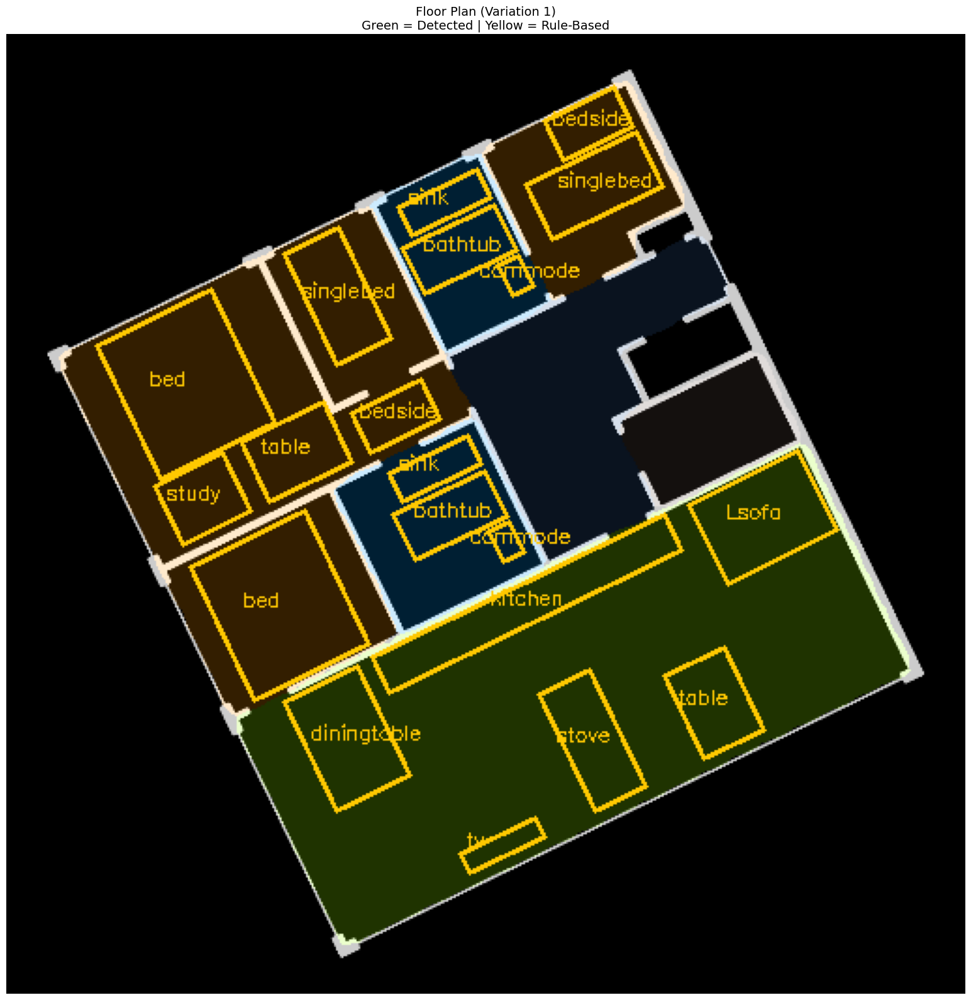

✓ Saved report: /content/drive/MyDrive/generated/optimal_furniture_placement/placement_report_variation_001.json

STEP 7: Creating visualization with ACTUAL furniture images
\n============================================================
GENERATING CLEAN FLOOR PLAN VISUALIZATION
✓ Detecting walls...
  Found 262144 wall pixels (100.0% of image)
✓ Extracted floor colors from LoRA images
    living_room: RGB(205, 175, 135)
    bedroom: RGB(185, 165, 145)
    bathroom: RGB(195, 205, 210)
    toilet: RGB(200, 208, 212)
    hallway: RGB(175, 165, 155)
    kitchen: RGB(210, 185, 155)
✓ Mapping rooms to floor colors...
✓ Filling rooms with floor colors...
✓ Drawing solid black walls...
✓ Placing furniture images...
✓ Placed 20 furniture items
✓ Adding room labels...
✓ Saved: /content/drive/MyDrive/generated/optimal_furniture_placement/floor_plan_actual_variation_001.png


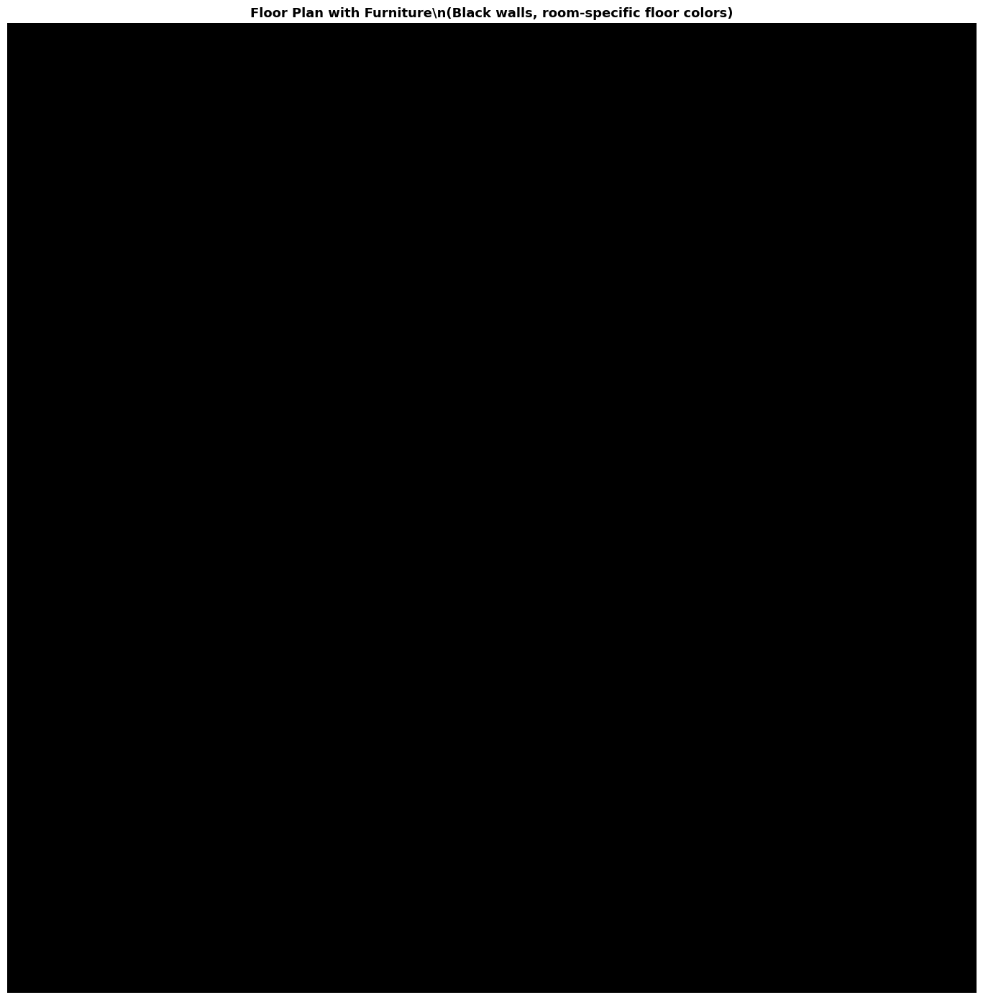

✓ Visualization complete!

################################################################################
# VARIATION 2/10
################################################################################

Selected LoRA images for variation 2:
  living_room: 00000010_living_room_1_rectangle_bottom_right_extracted_4.png
  bedroom: 00000010_bedroom_2_L-shaped_top_left_extracted_2.png
  bathroom: 00000010_bathroom_1_square_top_left_extracted_4.png
  hallway: 00000010_hallway_1_L-shaped_top_right_extracted_4.png
  toilet: 00000010_toilet_1_rectangle_top_right_extracted_3.png
FLOOR PLAN FURNITURE PLACEMENT (Variation 2)

STEP 1: Detecting furniture from LoRA outputs using YOLO
  Detecting in: 00000010_living_room_1_rectangle_bottom_right_extracted_4.png
    Found 10 items: kitchen, stove, L-sofa, tv, dining_table, door, table, table, L-sofa, L-sofa
  Detecting in: 00000010_bedroom_2_L-shaped_top_left_extracted_2.png
    Found 7 items: bed, bedside, door, dining_table, door, door, door
  De

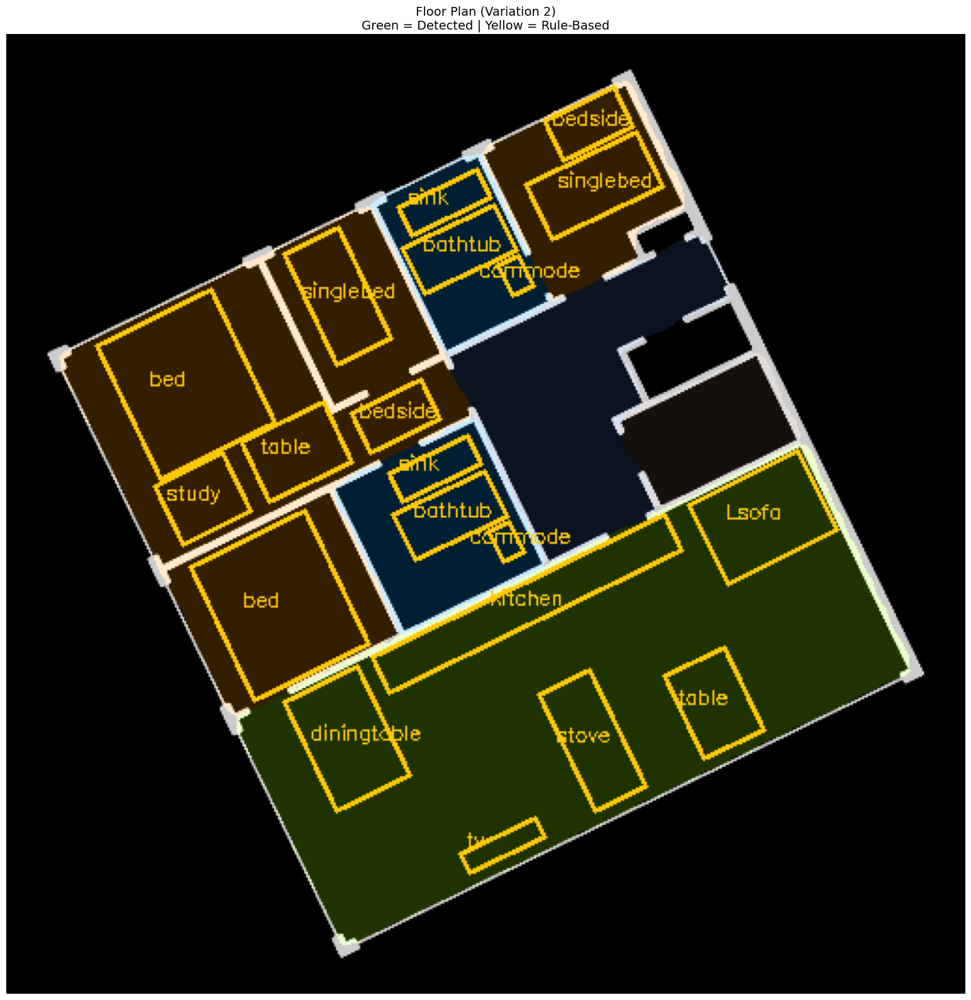

✓ Saved report: /content/drive/MyDrive/generated/optimal_furniture_placement/placement_report_variation_002.json

STEP 7: Creating visualization with ACTUAL furniture images
\n============================================================
GENERATING CLEAN FLOOR PLAN VISUALIZATION
✓ Detecting walls...
  Found 262144 wall pixels (100.0% of image)
✓ Extracted floor colors from LoRA images
    living_room: RGB(205, 175, 135)
    bedroom: RGB(185, 165, 145)
    bathroom: RGB(195, 205, 210)
    toilet: RGB(200, 208, 212)
    hallway: RGB(175, 165, 155)
    kitchen: RGB(210, 185, 155)
✓ Mapping rooms to floor colors...
✓ Filling rooms with floor colors...
✓ Drawing solid black walls...
✓ Placing furniture images...
✓ Placed 20 furniture items
✓ Adding room labels...
✓ Saved: /content/drive/MyDrive/generated/optimal_furniture_placement/floor_plan_actual_variation_002.png


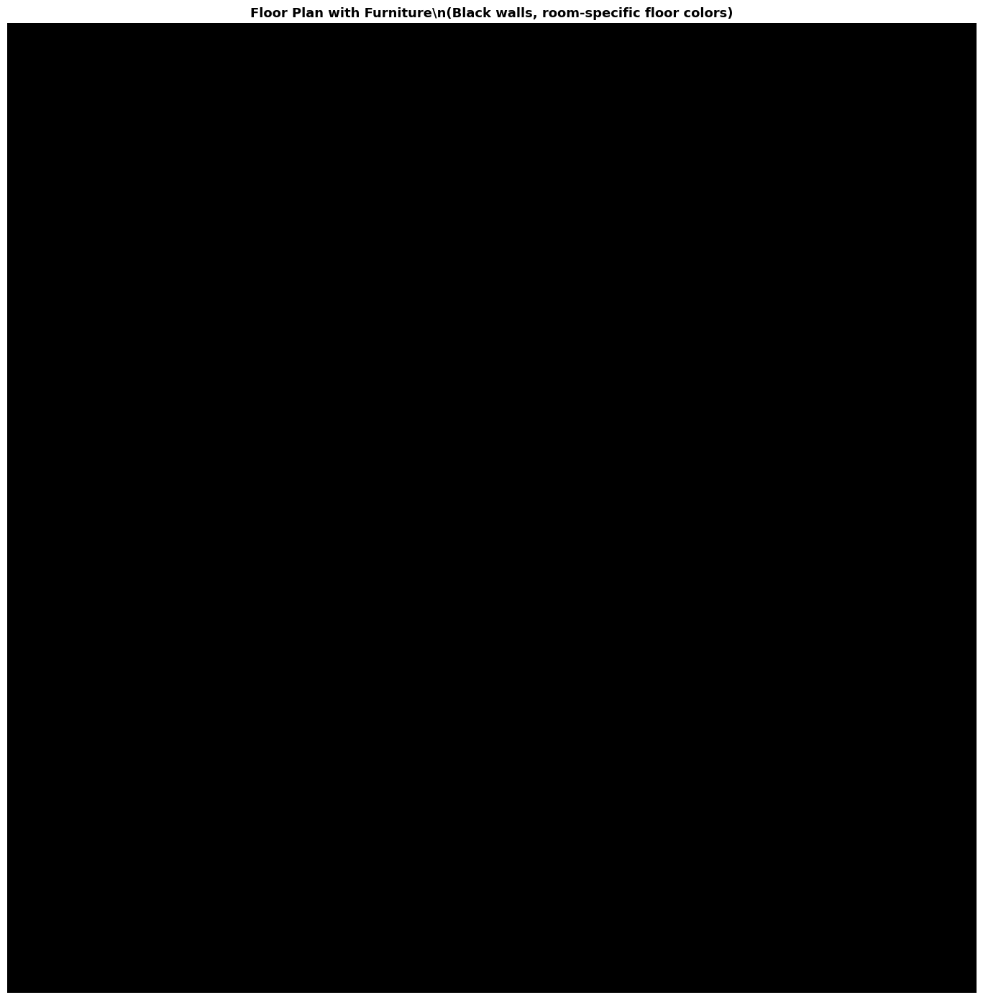

✓ Visualization complete!

################################################################################
# VARIATION 3/10
################################################################################

Selected LoRA images for variation 3:
  living_room: 00000010_living_room_1_rectangle_bottom_right_extracted_3.png
  bedroom: 00000010_bedroom_2_L-shaped_top_left_extracted_2.png
  bathroom: 00000010_bathroom_1_square_top_left_extracted_3.png
  hallway: 00000010_hallway_1_L-shaped_top_right_extracted_1.png
  toilet: 00000010_toilet_1_rectangle_top_right_extracted_2.png
FLOOR PLAN FURNITURE PLACEMENT (Variation 3)

STEP 1: Detecting furniture from LoRA outputs using YOLO
  Detecting in: 00000010_living_room_1_rectangle_bottom_right_extracted_3.png
    Found 14 items: chair, kitchen, chair, dining_table, chair, L-sofa, sofa, dining_table, table, table, table, stove, door, L-sofa
  Detecting in: 00000010_bedroom_2_L-shaped_top_left_extracted_2.png
    Found 7 items: bed, bedside, door,

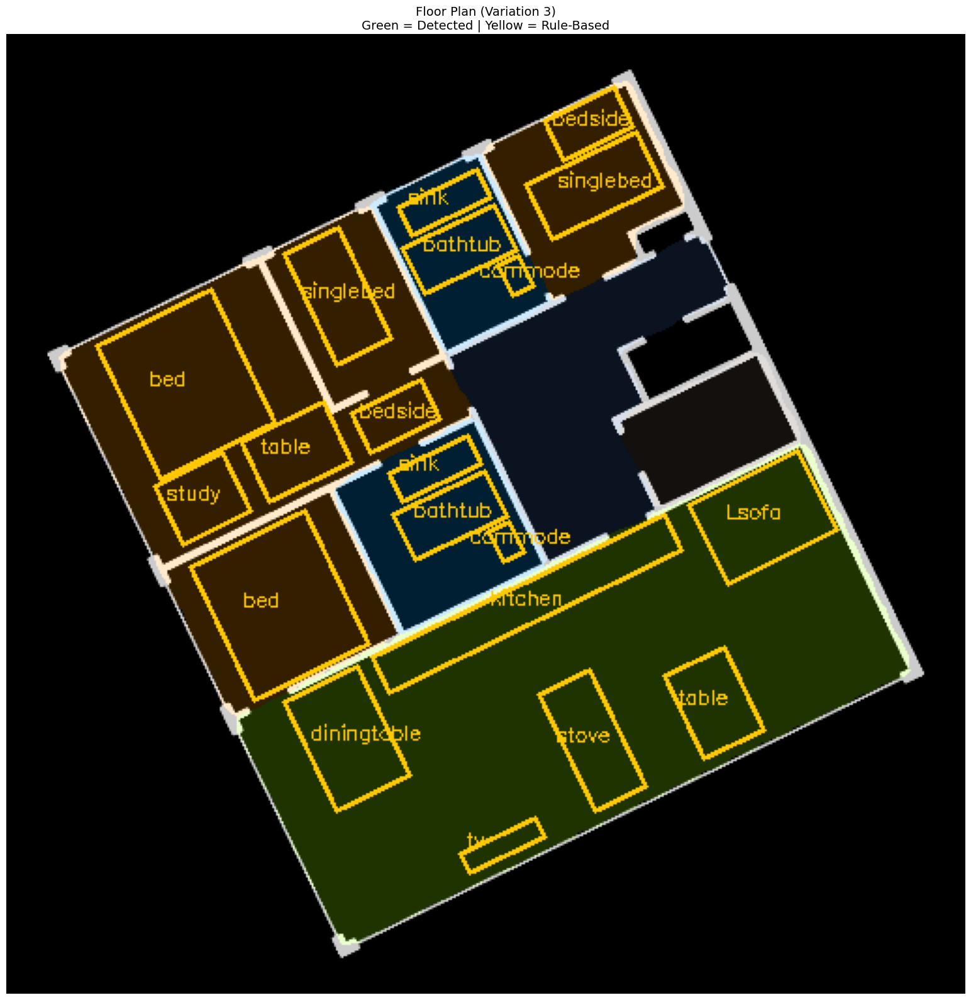

✓ Saved report: /content/drive/MyDrive/generated/optimal_furniture_placement/placement_report_variation_003.json

STEP 7: Creating visualization with ACTUAL furniture images
\n============================================================
GENERATING CLEAN FLOOR PLAN VISUALIZATION
✓ Detecting walls...
  Found 262144 wall pixels (100.0% of image)
✓ Extracted floor colors from LoRA images
    living_room: RGB(205, 175, 135)
    bedroom: RGB(185, 165, 145)
    bathroom: RGB(195, 205, 210)
    toilet: RGB(200, 208, 212)
    hallway: RGB(175, 165, 155)
    kitchen: RGB(210, 185, 155)
✓ Mapping rooms to floor colors...
✓ Filling rooms with floor colors...
✓ Drawing solid black walls...
✓ Placing furniture images...
✓ Placed 20 furniture items
✓ Adding room labels...
✓ Saved: /content/drive/MyDrive/generated/optimal_furniture_placement/floor_plan_actual_variation_003.png


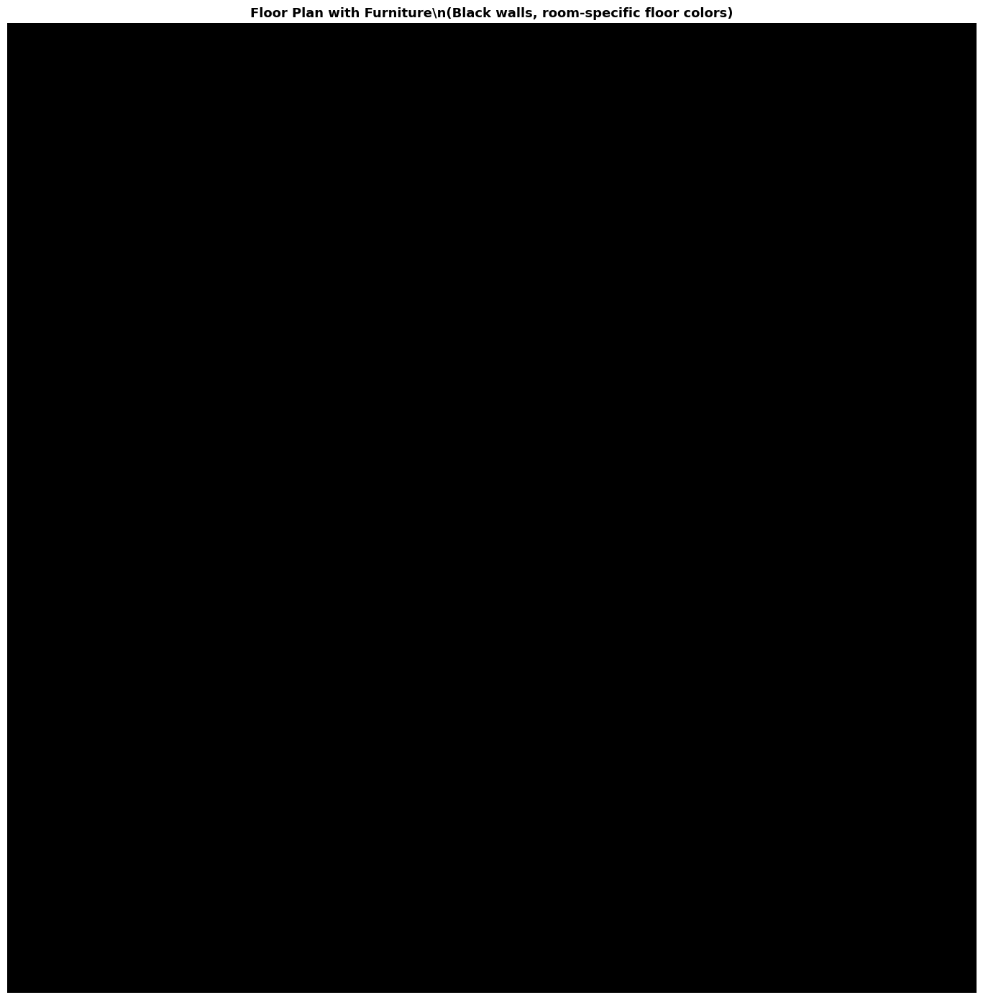

✓ Visualization complete!

################################################################################
# VARIATION 4/10
################################################################################

Selected LoRA images for variation 4:
  living_room: 00000010_living_room_1_rectangle_bottom_right_extracted_2.png
  bedroom: 00000010_bedroom_1_L-shaped_top_right_extracted_2.png
  bathroom: 00000010_bathroom_1_square_top_left_extracted_4.png
  hallway: 00000010_hallway_1_L-shaped_top_right_extracted_1.png
  toilet: 00000010_toilet_1_rectangle_top_right_extracted_1.png
FLOOR PLAN FURNITURE PLACEMENT (Variation 4)

STEP 1: Detecting furniture from LoRA outputs using YOLO
  Detecting in: 00000010_living_room_1_rectangle_bottom_right_extracted_2.png
    Found 18 items: chair, table, kitchen, chair, table, dining_table, chair, dining_table, door, chair, tv, stove, sofa, chair, door, sofa, chair, table
  Detecting in: 00000010_bedroom_1_L-shaped_top_right_extracted_2.png
    Found 5 ite

In [ ]:
# Set output folder for optimal furniture placement results
optimal_output_folder = '/content/drive/MyDrive/generated/optimal_furniture_placement'

# Path to furniture crops (actual furniture images)
furniture_crops_folder = '/content/drive/MyDrive/floor_planrules/furniture_crops'

# Number of variations to generate (uses different LoRA image combinations)
NUM_VARIATIONS = 10  # Change this to generate more/fewer variations

def get_next_variation_id(output_folder):
    """
    Find the next available variation ID by checking existing files.
    Returns the starting ID that won't conflict with existing files.
    """
    if not os.path.exists(output_folder):
        return 1
    
    existing_ids = set()
    
    # Check for existing variation files
    for filename in os.listdir(output_folder):
        # Match patterns like floor_plan_variation_001.png, placement_report_variation_005.json, etc.
        import re
        match = re.search(r'variation_(\d+)', filename)
        if match:
            existing_ids.add(int(match.group(1)))
    
    if not existing_ids:
        return 1
    
    # Return the next ID after the highest existing one
    return max(existing_ids) + 1


def generate_multiple_variations_with_offset(
    room_images,
    segmented_mask_path,
    furniture_json_path,
    output_folder,
    num_variations=10,
    pixel_to_meter_ratio=0.1,
    confidence_threshold=0.3,
    debug=False,
    furniture_crops_path=None,
    start_id=None
):
    """
    Generate multiple floor plan variations with auto-incrementing IDs.
    Avoids overwriting existing files by starting from the next available ID.
    """
    
    print("="*80)
    print(f"GENERATING {num_variations} FLOOR PLAN VARIATIONS")
    print("="*80)

    os.makedirs(output_folder, exist_ok=True)
    
    # Auto-detect starting ID if not provided
    if start_id is None:
        start_id = get_next_variation_id(output_folder)
        print(f"✓ Auto-detected starting ID: {start_id} (existing files preserved)")
    else:
        print(f"✓ Using provided starting ID: {start_id}")

    all_results = []

    # Get room types and their images
    room_types_available = list(room_images.keys())
    print(f"\nAvailable room types: {room_types_available}")
    for rt in room_types_available:
        print(f"  {rt}: {len(room_images[rt])} images")

    # Generate different combinations with offset IDs
    for i in range(num_variations):
        var_id = start_id + i  # Use offset ID
        
        print(f"\n{'#'*80}")
        print(f"# VARIATION {var_id} ({i+1}/{num_variations})")
        print(f"{'#'*80}")

        # Randomly select one image from each room type
        lora_images_for_variation = []
        selected_info = {}

        for room_type, images in room_images.items():
            if len(images) > 0:
                # Randomly pick one image
                img_path, _ = random.choice(images)
                lora_images_for_variation.append(img_path)
                selected_info[room_type] = os.path.basename(img_path)

        print(f"\nSelected LoRA images for variation {var_id}:")
        for rt, img_name in selected_info.items():
            print(f"  {rt}: {img_name}")

        try:
            # Generate this variation
            final_layout, result_image, report, actual_image = generate_floor_plan_with_optimal_furniture(
                lora_room_images=lora_images_for_variation,
                segmented_mask_path=segmented_mask_path,
                furniture_json_path=furniture_json_path,
                output_folder=output_folder,
                pixel_to_meter_ratio=pixel_to_meter_ratio,
                confidence_threshold=confidence_threshold,
                debug=debug,
                variation_id=var_id,  # Use the offset ID
                furniture_crops_path=furniture_crops_path,
                all_lora_room_images=room_images
            )

            all_results.append({
                'variation_id': var_id,
                'lora_images': selected_info,
                'layout': final_layout,
                'image': result_image,
                'actual_image': actual_image,
                'report': report,
                'success': True
            })

        except Exception as e:
            print(f"❌ Error generating variation {var_id}: {e}")
            all_results.append({
                'variation_id': var_id,
                'lora_images': selected_info,
                'success': False,
                'error': str(e)
            })

    # Summary of all variations
    print("\n" + "="*80)
    print("SUMMARY OF ALL VARIATIONS")
    print("="*80)

    successful = sum(1 for r in all_results if r['success'])
    print(f"\n✓ Successfully generated: {successful}/{num_variations} variations")
    print(f"  Variation IDs: {start_id} to {start_id + num_variations - 1}")

    for result in all_results:
        var_id = result['variation_id']
        if result['success']:
            total_furniture = sum(len(items) for items in result['layout'].values())
            print(f"  Variation {var_id}: {total_furniture} pieces of furniture")
        else:
            print(f"  Variation {var_id}: FAILED - {result.get('error', 'Unknown error')}")

    # Save summary report with timestamp to avoid conflicts
    from datetime import datetime
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    
    summary_report = {
        'generation_timestamp': timestamp,
        'total_variations': num_variations,
        'successful': successful,
        'start_id': start_id,
        'end_id': start_id + num_variations - 1,
        'variations': [
            {
                'id': r['variation_id'],
                'success': r['success'],
                'lora_images': r['lora_images'],
                'total_furniture': sum(len(items) for items in r['layout'].values()) if r['success'] else 0
            }
            for r in all_results
        ]
    }

    summary_path = os.path.join(output_folder, f'variations_summary_{start_id}_to_{start_id + num_variations - 1}.json')
    with open(summary_path, 'w') as f:
        json.dump(summary_report, f, indent=2)
    print(f"\n✓ Saved summary: {summary_path}")

    print("\n" + "="*80)
    print(f"✓ ALL {successful} VARIATIONS COMPLETE!")
    print(f"Results saved to: {output_folder}")
    print("="*80)

    return all_results


print("="*80)
print("GENERATING MULTIPLE FLOOR PLAN VARIATIONS (WITH AUTO-INCREMENT)")
print("="*80)
print(f"Will generate {NUM_VARIATIONS} variations using different LoRA image combinations")
print(f"Output folder: {optimal_output_folder}")
print(f"Furniture images: {furniture_crops_folder}")
print(f"NOTE: Existing files will be PRESERVED - new IDs will be auto-assigned")
print()

# Run multi-variation generation with auto-incrementing IDs
all_results = generate_multiple_variations_with_offset(
    room_images=selected_rooms,  # All loaded LoRA room images
    segmented_mask_path=segmented_rooms,
    furniture_json_path=furniture_json_path,
    output_folder=optimal_output_folder,
    num_variations=NUM_VARIATIONS,
    pixel_to_meter_ratio=0.1,
    confidence_threshold=0.25,
    debug=False,  # Set to True for detailed output per variation
    furniture_crops_path=furniture_crops_folder  # For actual furniture visualization
)

# Final summary
print("\n" + "="*80)
print("FINAL RESULTS")
print("="*80)

successful_count = sum(1 for r in all_results if r['success'])
print(f"Successfully generated: {successful_count}/{NUM_VARIATIONS} variations")

total_furniture_all = 0
for result in all_results:
    if result['success']:
        var_furniture = sum(len(items) for items in result['layout'].values())
        total_furniture_all += var_furniture
        detected = sum(1 for room_items in result['layout'].values()
                      for f in room_items if getattr(f, 'is_from_detection', False))
        rule_based = var_furniture - detected
        print(f"  Variation {result['variation_id']}: {var_furniture} items ({detected} detected, {rule_based} rule-based)")

print(f"\nAverage furniture per floor plan: {total_furniture_all/successful_count:.1f}" if successful_count > 0 else "")
print(f"\nAll results saved to: {optimal_output_folder}")
print("\nOutput files per variation:")
print("  - floor_plan_variation_XXX.png (schematic with colored boxes)")
print("  - floor_plan_actual_variation_XXX.png (with actual furniture images)")
print("  - placement_report_variation_XXX.json (detailed placement data)")
print("="*80)

In [ ]:
# Verification: Show what's in each room for all variations
print("="*80)
print("VERIFICATION: FURNITURE PLACEMENT BY ROOM (ALL VARIATIONS)")
print("="*80)

for result in all_results:
    if not result['success']:
        print(f"\n❌ Variation {result['variation_id']}: FAILED")
        continue

    final_layout = result['layout']
    var_id = result['variation_id']

    print(f"\n{'='*60}")
    print(f"VARIATION {var_id}")
    print(f"{'='*60}")

    all_correct = True

    for room_name, furniture_list in final_layout.items():
        room_type = room_name.split('_')[0]
        if 'living' in room_name:
            room_type = 'living_room'

        print(f"\n📍 {room_name.upper()} (type: {room_type})")

        if not furniture_list:
            if room_type in ['hallway', 'empty_room']:
                print("  ⬜ Empty (expected for hallway)")
            else:
                print("  ⚠️ EMPTY - should have furniture!")
                all_correct = False
            continue

        valid_for_room = CORRECTED_FURNITURE_ROOM_MAP.get(room_type, [])

        for furniture in furniture_list:
            source = "🟢" if getattr(furniture, 'is_from_detection', False) else "🟡"

            # Check if furniture belongs in this room
            is_valid = any(furniture.name.lower() in v.lower() or v.lower() in furniture.name.lower()
                          for v in valid_for_room)

            if is_valid:
                print(f"  ✓ {source} {furniture.name}")
            else:
                print(f"  ✗ {source} {furniture.name} - WRONG ROOM!")
                all_correct = False

    if all_correct:
        print(f"\n✅ Variation {var_id}: ALL FURNITURE CORRECTLY PLACED!")
    else:
        print(f"\n⚠️ Variation {var_id}: Some issues found")

print("\n" + "="*80)
print("LEGEND:")
print("  🟢 = Detected from LoRA/YOLO")
print("  🟡 = Rule-based placement")
print("  ⬜ = Empty (expected for hallways)")
print("="*80)

print("""
PLACEMENT RULES APPLIED:
✓ Sink: bathroom/toilet ONLY (not living room)
✓ Bed/study/bedside: bedroom ONLY
✓ Sofa/TV/table/kitchen: living_room ONLY
✓ Bathtub/shower/commode: bathroom ONLY
✓ ALL rooms filled with rule-based furniture (fresh copies)
✓ All furniture fully inside room boundaries
✓ No overlapping furniture
""")